# Домашнее задание 1. Свёртки, обучение глубоких сетей, adversarial robustness

**Дедлайн:** ДД.ММ.2026, 23:59 (3 недели).

- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры, cell metadata и открытые тесты сохраняйте; можно добавлять свои ячейки. Открытые тесты проверяют часть контракта, при оценке будут и другие входы в пределах условия.
- После вопроса приведите наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2–4 предложений; для составного вопроса можно ответить по пунктам. Отсутствие ожидаемого эффекта — допустимый результат, если эксперимент корректен и вы это обсудили.
- Разделы 1–4, 5.1 и 6 обязательны. В разделе 5 выберите **одну** задачу: 5.2 targeted или 5.3 transfer (`ATTACK_TRACK`). Обе дают по 2 балла; вторая ветка не добавляет баллы. Бонусы 7.1–7.5 выбираются отдельно через `BONUS_TASKS`; за бонусы суммарно можно получить до 4 баллов из 5 предложенных.
- `FAST_MODE = True` — проверка кода на небольшом бюджете; финальные эксперименты делаются с `False`. Не выбранная ветка и выключенные бонусы автоматически пропускаются, даже если их решения пустые.
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts`, который создаётся перед бонусами. Если сдаёте частичное решение, перечислите нерешённые задачи в ячейке ниже и приложите доступные результаты; ошибки и отсутствие зависимых результатов не скрывайте. Для частичной сдачи успешный Run All и полный каталог artifacts не требуются. Баллы выставляются по отдельным критериям, одна ошибка не обнуляет остальные задачи.
- Для CIFAR-10 рекомендуется CUDA GPU с 8 GB памяти или больше; подойдёт Colab T4. FashionMNIST тоже удобно считать на GPU: adversarial training и серии PGD могут занимать десятки минут и дольше на CPU. Реальное время зависит от устройства; замеряйте его в своих прогонах. Бонусы не входят в основной бюджет.
- Можно пользоваться документацией PyTorch и материалами курса. Нельзя вызывать готовую реализацию того, что просят написать (`torch.optim.AdamW` внутри `MyAdamW`, `nn.BatchNorm2d` внутри `MyBatchNorm2d` и т.п.). Повторно использовать код семинаров можно, указав источник.
- В обучающих моделях используйте библиотечные `nn.Conv2d` и `nn.BatchNorm2d`; собственные слои из разделов 1–2 проверяются отдельно. В `train_cifar` нужен ваш `MyAdamW`.

| раздел | задачи | баллы |
|---|---|---|
| 1. Свёртка изнутри | 1.1 `unfold` · 1.2 backward · 1.3 RF и effective RF | 3.5 |
| 2. Нормализация | 2.1 `BatchNorm2d` · 2.2 Conv–BN fusion | 2 |
| 3. Инициализация и optimizer | 3.1 масштаб активаций · 3.2 `AdamW` · 3.3 cosine schedule | 3 |
| 4. ResNet на CIFAR-10 | 4.1 архитектура · 4.2 обучение · 4.3 plain-20 vs plain-56 | 4.5 |
| 5. Атаки | 5.1 PGD-$L_2$ и **одна** из 5.2 / 5.3 | 3 |
| 6. Adversarial training | 6.1 PGD-AT · 6.2 диагностика · 6.3 input gradients | 4 |
| 7*. Бонусы | 7.1 edge of stability · 7.2 FFT · 7.3 Muon · 7.4 $L_0$ · 7.5 catastrophic overfitting | до +4 |
| итого | | 20 + 4 |

Внутри задачи отдельно оцениваются код, эксперимент и объяснение; разбивка указана у каждого задания. Для вычислительного эксперимента нужны корректный протокол и сохранённые результаты, для объяснения — опора на ваши числа и понимание ограничений. Конкретная accuracy и совпадение с «ожидаемой картинкой» сами по себе не являются критерием балла.

Примерный порядок на три недели: первая — разделы 1–3; вторая — CIFAR-10 и выбранная задача об атаках; третья — adversarial training, анализ результатов и финальный прогон.

**Сведения о сдаче.**

разделы 1–4, 5.1 и 6; выбрана ветка 5.2 (`ATTACK_TRACK='targeted'`). Ветка 5.3 и бонусы не выбраны (`BONUS_TASKS=set()`).

Эксперименты выполнены в CUDA, `FAST_MODE=False`. Основной seed — 0. CIFAR-10: 50 000 train и 10 000 test, ResNet-20 — 20 эпох, plain-20/plain-56 — по 10 эпох. FashionMNIST: 60 000 train и первые 1000 test, стандартная CNN и PGD-7-AT — по 5 эпох.(Диагностика усиленных атак использует первые 256 test-объектов). Разделы 1–3 работают с CPU-тензорами по коду задания.

Сохранённые outputs =прохождение открытых тестов, завершение обучения и выполнение экспорта `metrics.json`, `resnet20.pt`, `fashion_standard.pt`, `fashion_pgd_at.pt` в `artifacts/`

Внешний код семинаров сверх включённого шаблона не добавлялся


In [ ]:
# При необходимости, в отдельном окружении: %pip install -r requirements.txt
import copy
import itertools
import json
import math
from pathlib import Path
import time
import timeit

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import gradcheck
from torchvision import datasets

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available:  {torch.cuda.is_available()}')
print(f'MPS available:   {torch.backends.mps.is_available()}')

PyTorch version: 2.11.0+cu130
CUDA available:  True
MPS available:   False


In [ ]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)


device = get_device()
set_seed(0)
device

device(type='cuda')

In [ ]:
FAST_MODE = False   # True — отладка, False — финальный прогон
DATA_ROOT = './data'
ATTACK_TRACK = 'targeted'   # 'targeted' (5.2) или 'transfer' (5.3)
BONUS_TASKS = set()        # например {'7.2', '7.4'}; пустое множество отключает все бонусы
assert ATTACK_TRACK in {'targeted', 'transfer'}
assert BONUS_TASKS <= {'7.1', '7.2', '7.3', '7.4', '7.5'}
RUN_TIMES = {}

Общие функции для разделов 4–7: данные лежат одним тензором на `device`, батчи режутся индексами (без `DataLoader` — так быстрее для маленьких картинок).

In [ ]:
def iterate_batches(X, Y, batch_size, shuffle=True, transform=None):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for start in range(0, len(X), batch_size):
        b = idx[start:start + batch_size]
        yield (X[b] if transform is None else transform(X[b])), Y[b]


@torch.no_grad()
def predict_logits(model, X, batch_size=1000, transform=None):
    model.eval()
    return torch.cat([model(X[i:i + batch_size] if transform is None else transform(X[i:i + batch_size]))
                      for i in range(0, len(X), batch_size)])


def accuracy(logits, Y):
    return (logits.argmax(dim=1) == Y).float().mean().item()


def n_params(model):
    return sum(p.numel() for p in model.parameters())

---
# 1. Свёртка изнутри

## 1.1 `conv2d` через `unfold` (1 балл)

`F.unfold` (im2col) вырезает все патчи, которые видит ядро, и кладёт каждый патч столбцом:
$$
\mathrm{cols}[b,\, (c, u, v),\, \ell] = x_{\mathrm{pad}}\big[b,\, c,\; s\, i_\ell + d\, u,\; s\, j_\ell + d\, v\big], \qquad
\mathrm{cols} \in \mathbb R^{B \times C_{\text{in}} k_h k_w \times L}, \quad L = H_{\text{out}} W_{\text{out}},
$$
где $(i_\ell, j_\ell)$ — позиция $\ell$-го выхода. После этого свёртка — одно матричное умножение:
$$
y[b, o, \ell] = \sum_{(c, u, v)} W[o, (c, u, v)]\; \mathrm{cols}[b, (c, u, v), \ell] + \mathrm{bias}[o].
$$
С `groups = g` каналы делятся на $g$ групп: строки $\mathrm{cols}$ разбиваются на $g$ блоков по $\frac{C_{\text{in}}}{g} k_h k_w$, веса — на $g$ блоков по $\frac{C_{\text{out}}}{g}$ выходов, и каждая группа умножается только на свой блок.

Реализуйте `conv2d_unfold` для 4D-входа: stride, padding и dilation — целые числа или пары, groups — положительное целое, bias может быть `None`. Строковые padding и complex dtype не требуются. Циклов по батчу, каналам и позициям быть не должно.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [ ]:
def pair(v):
    return v if isinstance(v, tuple) else (v, v)


def conv_output_size(size, kernel_size, stride=1, padding=0, dilation=1):
    return (size + 2 * padding - dilation * (kernel_size - 1) - 1) // stride + 1


def conv_output_shape(hw, kernel_size, stride=1, padding=0, dilation=1):
    params = zip(hw, pair(kernel_size), pair(stride), pair(padding), pair(dilation))
    return tuple(conv_output_size(*p) for p in params)

In [ ]:
def conv2d_unfold(x, weight, bias=None, stride=1, padding=0, dilation=1, groups=1):
    B, C_in, H, W = x.shape
    C_out, cg, kh, kw = weight.shape
    if groups < 1 or C_in != cg * groups or C_out % groups:
        raise ValueError('Несовместимые каналы и groups')
    oh, ow = conv_output_shape((H, W), (kh, kw), stride, padding, dilation)
    cols = F.unfold(x, (kh, kw), dilation=dilation, padding=padding, stride=stride)
    cols = cols.reshape(B, groups, cg * kh * kw, oh * ow)
    w = weight.reshape(groups, C_out // groups, cg * kh * kw)
    out = torch.einsum('goc,bgcl->bgol', w, cols).reshape(B, C_out, oh, ow)
    return out if bias is None else out + bias[None, :, None, None]


In [ ]:
torch.manual_seed(0)
x = torch.randn(2, 6, 11, 14)
n_checked = 0
for k, s, p, d, g in itertools.product([1, 3, (3, 5)], [1, 2, (2, 1)], [0, 1, (2, 1)], [1, 2], [1, 2, 3, 6]):
    if min(conv_output_shape((11, 14), k, s, p, d)) <= 0:
        continue
    w, b = torch.randn(12, 6 // g, *pair(k)), torch.randn(12)
    ref = F.conv2d(x, w, b, stride=s, padding=p, dilation=d, groups=g)
    assert torch.allclose(conv2d_unfold(x, w, b, s, p, d, g), ref, atol=1e-4), (k, s, p, d, g)
    assert torch.allclose(conv2d_unfold(x, w, None, s, p, d, g), ref - b[None, :, None, None], atol=1e-4)
    n_checked += 1
n_checked

216

**Вопрос.** Во сколько раз `cols` больше входа $x$ при $k = 3, 5, 7$ и `padding = k // 2`? Как стоимость im2col по памяти соотносится с тем, что FFT-свёртка выигрывает именно на больших ядрах?

In [ ]:
x = torch.randn(8, 64, 32, 32)
for k in [3, 5, 7]:
    print(f'k = {k}: cols / x = {F.unfold(x, k, padding=k // 2).numel() / x.numel():.1f}')

k = 3: cols / x = 9.0
k = 5: cols / x = 25.0
k = 7: cols / x = 49.0


**Ответ.** При k = 3, 5 и 7 массив cols больше входа в 9, 25 и 49 раз соответственно. При stride = 1 и таком padding число положений ядра равно H·W, а для каждого положения сохраняются k² значений на канал. Поэтому расход памяти растёт пропорционально k²: одни и те же пиксели многократно копируются в соседние окна.

FFT-свёртка не создаёт такой массив окон, но требует дополнительных вычислений для перехода в частотную область и обратно. На маленьких ядрах эти затраты могут быть больше выигрыша, а на больших FFT становится выгоднее. Точный результат зависит от размеров данных и реализации


## 1.2 Backward свёртки руками (1.5 балла)

Свёртка линейна по входу: $\mathrm{vec}(y) = M\, \mathrm{vec}(x) + b$ с разреженной матрицей $M$, в строках которой стоят веса ядра. Для $g = \partial L / \partial y$:
$$
\frac{\partial L}{\partial x} = M^\top g = \texttt{conv\_transpose2d}(g, W), \qquad
\frac{\partial L}{\partial W}[o, (c,u,v)] = \sum_{b,\ell} g[b, o, \ell]\; \mathrm{cols}[b, (c,u,v), \ell], \qquad
\frac{\partial L}{\partial b}[o] = \sum_{b, i, j} g[b, o, i, j].
$$
При stride $s > 1$ разные $H$ дают одинаковый $H_{\text{out}}$, и `conv_transpose2d` не знает, какой размер восстанавливать: нужную форму выбирает `output_padding`
$$
\mathrm{op}_H = H - \big((H_{\text{out}} - 1)s - 2p + k_h\big).
$$

Допишите `backward` (stride и padding — целые числа, dilation = 1, groups = 1). Проверка — `gradcheck` в float64 на размерах, где `output_padding` не равен нулю.

**Оценивание:** код — 1.2; эксперимент — 0; объяснение — 0.3 балла.

In [ ]:
class Conv2dFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, weight, bias, stride, padding):
        ctx.save_for_backward(x, weight)
        ctx.stride, ctx.padding = stride, padding
        ctx.has_bias = bias is not None
        return F.conv2d(x, weight, bias, stride=stride, padding=padding)

    @staticmethod
    def backward(ctx, grad_out):
        x, weight = ctx.saved_tensors
        s, p = ctx.stride, ctx.padding
        kh, kw = weight.shape[-2:]
        oh, ow = grad_out.shape[-2:]
        op = (x.shape[-2] - ((oh - 1) * s - 2 * p + kh),
              x.shape[-1] - ((ow - 1) * s - 2 * p + kw))
        grad_x = F.conv_transpose2d(grad_out, weight, stride=s, padding=p, output_padding=op)
        cols = F.unfold(x, (kh, kw), padding=p, stride=s)
        grad_w = torch.einsum('bol,bcl->oc', grad_out.flatten(2), cols).reshape_as(weight)
        grad_b = grad_out.sum((0, 2, 3)) if ctx.has_bias else None
        return grad_x, grad_w, grad_b, None, None


In [ ]:
torch.manual_seed(0)
n_checked = 0
for s, p, (H, W) in itertools.product([1, 2, 3], [0, 1, 2], [(7, 7), (8, 9), (10, 6)]):
    x = torch.randn(2, 3, H, W, dtype=torch.float64, requires_grad=True)
    w = torch.randn(4, 3, 3, 3, dtype=torch.float64, requires_grad=True)
    b = torch.randn(4, dtype=torch.float64, requires_grad=True)
    assert gradcheck(lambda x, w, b: Conv2dFunction.apply(x, w, b, s, p), (x, w, b)), (s, p, H, W)
    n_checked += 1
n_checked

27

**Вопрос.** Приведите два размера $H$, для которых свёртка $3 \times 3$ со stride 2 и padding 1 даёт одинаковый $H_{\text{out}}$, и `output_padding` для каждого.

**Ответ.** Например, можно взять H = 7 и H = 8: в обоих случаях после свёртки получится H_out = 4. Транспонированная свёртка без дополнительного padding даёт размер (4 − 1) · 2 − 2 + 3 = 7. Поэтому для H = 7 нужен output_padding = 0, а для H = 8 — output_padding = 1. Этот параметр позволяет получить нужный размер выхода, но не восстанавливает информацию, потерянную при свёртке.

## 1.3 Receptive field через autograd (1 балл)

Теоретический receptive field (RF) нейрона — область входа, потенциально влияющая на него по архитектуре. Носитель градиента на конкретном входе может быть меньше из-за ReLU, MaxPool или взаимных сокращений. Размер bounding box теоретического RF вдали от границ даёт рекурсия (функция `receptive_field` ниже) по слоям с ядром $k_l$, stride $s_l$ и dilation $d_l$:
$$
k_l^{\mathrm{eff}} = 1 + d_l (k_l - 1), \qquad r_0 = j_0 = 1, \qquad r_l = r_{l-1} + (k_l^{\mathrm{eff}} - 1)\, j_{l-1}, \qquad j_l = j_{l-1}\, s_l,
$$
$j_l$ — расстояние между соседними нейронами слоя $l$ в пикселях входа. Pooling считается так же.

Сети для проверки — свёртки с усредняющими ядрами (все веса $1/k^2$, bias 0) и `AvgPool`, без нелинейностей.

Реализуйте `empirical_rf`: по градиенту суммы каналов центрального выхода по входу найти размер bounding box ненулевых пикселей по высоте и ширине.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [ ]:
def receptive_field(layers):
    # layers: список dict(k, s=1, d=1); возвращает (r, j) после каждого слоя
    r, j = 1, 1
    history = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        r = r + (1 + d * (k - 1) - 1) * j
        j = j * s
        history.append((r, j))
    return history


def make_avg_net(layers, max_pool=False):
    modules = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        if layer.get('pool'):
            modules.append(nn.MaxPool2d(k, s) if max_pool else nn.AvgPool2d(k, s))
        else:
            conv = nn.Conv2d(1, 1, k, stride=s, dilation=d)
            nn.init.constant_(conv.weight, 1 / k ** 2)
            nn.init.zeros_(conv.bias)
            modules.append(conv)
    return nn.Sequential(*modules)


RF_ARCHS = {
    'conv3x3 x4': [dict(k=3)] * 4,
    'conv-pool':  [dict(k=3), dict(k=2, s=2, pool=True), dict(k=3), dict(k=2, s=2, pool=True), dict(k=3)],
    'strided':    [dict(k=5, s=2), dict(k=3, s=2), dict(k=3)],
    'dilated':    [dict(k=3, d=1), dict(k=3, d=2), dict(k=3, d=4)],
}

In [ ]:
def empirical_rf(model, in_channels=1, size=96):
    param = next(model.parameters(), None)
    opts = {} if param is None else dict(device=param.device, dtype=param.dtype)
    x = torch.randn(1, in_channels, size, size, **opts, requires_grad=True)
    out = model(x)
    g, = torch.autograd.grad(out[:, :, out.shape[-2] // 2, out.shape[-1] // 2].sum(), x)
    points = g.abs().sum((0, 1)).ne(0).nonzero()
    if not len(points):
        return (0, 0)
    return tuple((points.max(0).values - points.min(0).values + 1).tolist())


In [ ]:
torch.manual_seed(0)
for name, layers in RF_ARCHS.items():
    r = receptive_field(layers)[-1][0]
    assert empirical_rf(make_avg_net(layers)) == (r, r), name
    print(f'{name:<12} r = {r:>3}   MaxPool instead of AvgPool: {empirical_rf(make_avg_net(layers, max_pool=True))}')

conv3x3 x4   r =   9   MaxPool instead of AvgPool: (9, 9)
conv-pool    r =  18   MaxPool instead of AvgPool: (18, 18)
strided      r =  17   MaxPool instead of AvgPool: (17, 17)
dilated      r =  15   MaxPool instead of AvgPool: (15, 15)


**Вопрос.** Почему для проверки взяты усредняющие ядра без нелинейностей? Что меняется с `MaxPool` и почему?

**Ответ.** Усредняющие ядра взяты, чтобы все пиксели внутри рецептивного поля влияли на результат. Их веса положительные, поэтому вклады не компенсируют друг друга. Нелинейности тоже убраны, чтобы они не обнуляли градиент. В таком случае размер области с ненулевым градиентом совпадает с теоретическим RF: для четырёх сетей получились 9, 18, 17 и 15 пикселей.

С MaxPool градиент проходит только через максимальный элемент каждого окна. Поэтому набор влияющих пикселей зависит от входа, а область может содержать пропуски или стать меньше. У меня для сети conv-pool её размер всё равно составил 18 × 18. Это возможно ведь даже если внутри области есть пропуски, крайние пиксели с ненулевым градиентом могут остаться на тех же местах.

### Effective receptive field

Для рассматриваемых усредняющих сетей носитель градиента совпадает с теоретическим RF, но вклад пикселей неравномерный. Для стопки из $L$ усредняющих свёрток $3 \times 3$ карта $\partial y_{\text{center}} / \partial x$ — это $L$-кратная свёртка равномерного ядра, то есть распределение суммы $L$ независимых равномерных величин на $\{-1, 0, 1\}$ по каждой оси:
$$
\sigma_{\text{ERF}} = \sqrt{L \cdot \tfrac23}, \qquad r_L = 2L + 1.
$$
По ЦПТ профиль близок к гауссовскому, и эффективная ширина растёт как $\sqrt L$: [Understanding the Effective Receptive Field in Deep Convolutional Neural Networks](https://arxiv.org/pdf/1701.04128), Luo et al., 2016.

Реализуйте `erf_std`: $|\nabla_x y_{\text{center}}|$, усреднённый по `n_inputs` случайным входам и просуммированный по каналам, нормировать в распределение по строкам и вернуть его стандартное отклонение (в пикселях).

In [ ]:
def erf_std(model, in_channels=1, size=96, n_inputs=1):
    param = next(model.parameters(), None)
    opts = {} if param is None else dict(device=param.device, dtype=param.dtype)
    mass = torch.zeros(size, size, **opts)
    for _ in range(n_inputs):
        x = torch.randn(1, in_channels, size, size, **opts, requires_grad=True)
        out = model(x)
        g, = torch.autograd.grad(out[:, :, out.shape[-2] // 2, out.shape[-1] // 2].sum(), x)
        mass += g.detach().abs().sum((0, 1)) / n_inputs
    rows = mass.sum(1)
    if rows.sum() == 0:
        raise ValueError('Нулевая масса градиента')
    prob = rows / rows.sum()
    positions = torch.arange(size, device=mass.device, dtype=mass.dtype)
    mean = (positions * prob).sum()
    return ((positions - mean).square() * prob).sum().sqrt().item()


In [ ]:
for L in [1, 2, 4, 8, 16]:
    assert abs(erf_std(make_avg_net([dict(k=3)] * L)) - math.sqrt(2 * L / 3)) < 1e-3, L

Теперь обычная сеть: $L$ свёрток $3 \times 3$ по 16 каналов, ReLU, веса из $\mathcal N(0,\, 2 / \text{fan\_in})$, среднее по 16 входам.

In [ ]:
def make_relu_net(L, width=16, seed=0):
    torch.manual_seed(seed)
    layers, c = [], 1
    for _ in range(L):
        conv = nn.Conv2d(c, width, 3)
        nn.init.kaiming_normal_(conv.weight, nonlinearity='relu')
        nn.init.zeros_(conv.bias)
        layers += [conv, nn.ReLU()]
        c = width
    return nn.Sequential(*layers)


depths = [1, 2, 4, 8, 16]
erf = {'theoretical RF / 2': [float(L) for L in depths],
       'ERF std, averaging kernels': [erf_std(make_avg_net([dict(k=3)] * L)) for L in depths],
       'ERF std, random ReLU net': [erf_std(make_relu_net(L), n_inputs=16) for L in depths]}
for name, values in erf.items():
    print(f'{name:<28}' + ''.join(f'{v:>7.2f}' for v in values))

theoretical RF / 2             1.00   2.00   4.00   8.00  16.00
ERF std, averaging kernels     0.82   1.15   1.63   2.31   3.27
ERF std, random ReLU net       0.79   1.29   1.97   3.08   4.44


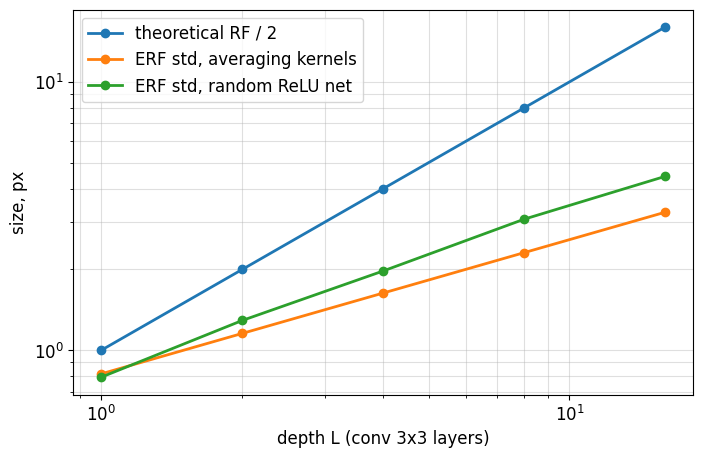

In [ ]:
plt.figure(figsize=(8, 5))
for name, values in erf.items():
    plt.loglog(depths, values, 'o-', linewidth=2, label=name)
plt.xlabel('depth L (conv 3x3 layers)')
plt.ylabel('size, px')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Как отношение эффективного RF к теоретическому меняется с глубиной (наклоны на log-log графике)? Как ведёт себя сеть с ReLU по сравнению с усредняющей?

**Ответ.** С увеличением глубины эффективное рецептивное поле растёт медленнее теоретического. У усредняющей сети его размер, измеренный через std, равен √(2L/3), а теоретический радиус равен L. Поэтому на log-log графике наклоны составляют 0,5 и 1 соответственно. Отношение эффективного размера к теоретическому радиусу уменьшается с 0,816 при одном слое до 0,204 при 16 слоях.

У сети с ReLU наблюдается похожая зависимость: это отношение снижается с 0,793 до 0,278. Наклон по крайним точкам составляет примерно 0,62, то есть эффективное поле тоже растёт медленнее глубины, но несколько быстрее, чем у усредняющей сети. Начиная с двух слоёв, оно получается шире, чем у усредняющей сети. Эти результаты получены для одного набора весов с усреднением по 16 входам, поэтому при другой инициализации числа могут отличаться.

In [ ]:
# Численные наблюдения по фактическому запуску
print('ReLU ERF:', erf['ERF std, random ReLU net'])
print('ReLU ERF / radius:', np.array(erf['ERF std, random ReLU net']) / np.array(depths))


ReLU ERF: [0.793458878993988, 1.2906243801116943, 1.9735690355300903, 3.0773661136627197, 4.443140506744385]
ReLU ERF / radius: [0.79345888 0.64531219 0.49339226 0.38467076 0.27769628]


---
# 2. Нормализация

## 2.1 `BatchNorm2d` с нуля (1 балл)

В `train()`: статистики текущего батча по каналу (среднее по $b, h, w$), нормировка смещённой дисперсией и обновление буферов
$$
\hat\mu \leftarrow (1 - m)\,\hat\mu + m\, \mu_{\text{batch}}, \qquad
\hat\sigma^2 \leftarrow (1 - m)\,\hat\sigma^2 + m\, \frac{n}{n - 1}\, \sigma^2_{\text{batch}}, \qquad n = BHW,
$$
в running-дисперсию идёт несмещённая оценка. В `eval()` — нормировка по $\hat\mu, \hat\sigma^2$. Параметры `weight` ($\gamma$) и `bias` ($\beta$), буферы `running_mean`, `running_var`, `num_batches_tracked` — с теми же именами, что в `nn.BatchNorm2d`, чтобы `load_state_dict` был совместим.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [ ]:
class MyBatchNorm2d(nn.Module):
    def __init__(self, num_features, eps=1e-5, momentum=0.1):
        super().__init__()
        self.eps, self.momentum = eps, momentum
        self.weight = nn.Parameter(torch.ones(num_features))
        self.bias = nn.Parameter(torch.zeros(num_features))
        self.register_buffer('running_mean', torch.zeros(num_features))
        self.register_buffer('running_var', torch.ones(num_features))
        self.register_buffer('num_batches_tracked', torch.tensor(0, dtype=torch.long))

    def forward(self, x):
        if x.ndim != 4:
            raise ValueError('Ожидается 4D вход')
        if self.training:
            count = x.numel() // x.shape[1]
            if count <= 1:
                raise ValueError('Нужно больше одного значения на канал')
            var, mean = torch.var_mean(x, dim=(0, 2, 3), unbiased=False)
            with torch.no_grad():
                self.num_batches_tracked.add_(1)
                m = self.momentum if self.momentum is not None else 1 / self.num_batches_tracked.item()
                self.running_mean.lerp_(mean.detach(), m)
                self.running_var.lerp_(var.detach() * count / (count - 1), m)
        else:
            mean, var = self.running_mean, self.running_var
        shape = (1, -1, 1, 1)
        return (x - mean.view(shape)) * torch.rsqrt(var.view(shape) + self.eps) * self.weight.view(shape) + self.bias.view(shape)


In [ ]:
torch.manual_seed(0)
mine, ref = MyBatchNorm2d(8), nn.BatchNorm2d(8)
assert set(dict(mine.named_parameters())) == {'weight', 'bias'}
assert set(dict(mine.named_buffers())) == {'running_mean', 'running_var', 'num_batches_tracked'}
with torch.no_grad():
    for m in (mine, ref):
        m.weight.copy_(torch.linspace(0.5, 2, 8))
        m.bias.copy_(torch.linspace(-1, 1, 8))

for step in range(10):
    x = (torch.randn(4, 8, 5, 5) * 3 + 2).requires_grad_(True)
    out_mine, out_ref = mine(x), ref(x)
    assert torch.allclose(out_mine, out_ref, atol=1e-5), step
    g = torch.randn_like(out_ref)
    grads_mine = torch.autograd.grad(out_mine, (x, mine.weight, mine.bias), g)
    grads_ref = torch.autograd.grad(out_ref, (x, ref.weight, ref.bias), g)
    assert all(torch.allclose(a, b, atol=1e-4) for a, b in zip(grads_mine, grads_ref)), step

for name, buf in ref.named_buffers():
    assert torch.allclose(getattr(mine, name).float(), buf.float(), atol=1e-5), name

mine.eval(), ref.eval()
x = torch.randn(4, 8, 5, 5)
assert torch.allclose(mine(x), ref(x), atol=1e-5)
mine.load_state_dict(ref.state_dict())

<All keys matched successfully>

**Вопрос.** Почему в running-дисперсию идёт несмещённая оценка, а в нормировку батча — смещённая? Насколько они различаются при $B = 4$ и карте $5 \times 5$, и при $B = 2$ и карте $1 \times 1$?

**Ответ.** Для нормировки батча используется смещённая дисперсия, потому что нужно нормировать значения этого конкретного батча: сумма квадратов отклонений делится на число значений n. Для running_var нужна оценка дисперсии всего распределения данных. Деление на n в среднем занижает её, поэтому используется поправка n/(n − 1), то есть деление на n − 1.

При B = 4 и карте 5 × 5 получаем n = 4 · 5 · 5 = 100. Несмещённая дисперсия больше смещённой в 100/99 ≈ 1,0101 раза — примерно на 1,01%. При B = 2 и карте 1 × 1 получаем n = 2, поэтому несмещённая дисперсия больше ровно в 2 раза.

## 2.2 Слияние свёртки и BatchNorm для инференса (1 балл)

В `eval()` BN — поканальное аффинное преобразование с фиксированными $\hat\mu, \hat\sigma^2$, поэтому $\mathrm{BN}(\mathrm{conv}(x))$ — снова свёртка с другими весами $W'$ и bias $b'$.

1. Выведите $W'$ и $b'$ в ячейке «Ответ» ниже.
2. Реализуйте `fuse_conv_bn(conv, bn)`, возвращающую новую `nn.Conv2d`: сохраняются `dtype`, `device`, `padding_mode`, `groups`, stride, padding и dilation; bias у исходной свёртки может отсутствовать. Входные модули в `eval()`, BN с affine и running statistics; исходные веса не менять.
3. Реализуйте `fuse_sequential(seq)` для плоского `nn.Sequential` в `eval()`: каждую соседнюю пару `Conv2d, BatchNorm2d` заменить свёрткой. Остальные модули скопировать через `copy.deepcopy`, исходную сеть не менять; рекурсивный обход вложенных контейнеров не требуется.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

**Ответ.** Для одного выходного канала результат свёртки можно записать как y = W * x + b. В режиме eval() BatchNorm использует сохранённые среднее μ и дисперсию σ²:

BN(y) = γ · (y − μ) / √(σ² + ε) + β.

Подставим сюда результат свёртки и сгруппируем слагаемые:

BN(W * x + b) = (γ / √(σ² + ε)) · W * x + γ · (b − μ) / √(σ² + ε) + β.

Получается обычная свёртка с новыми параметрами:

W′ = γ · W / √(σ² + ε),

b′ = γ · (b − μ) / √(σ² + ε) + β.

Если у исходной свёртки нет bias, в формуле берём b = 0. Веса и смещение пересчитываются отдельно для каждого выходного канала с его параметрами BatchNorm. Это работает и для групповой свёртки, поскольку связи между каналами не меняются.


In [ ]:
@torch.no_grad()
def fuse_conv_bn(conv, bn):
    if conv.training or bn.training:
        raise ValueError('Слияние требует eval()')
    fused = copy.deepcopy(conv)
    scale = bn.weight / torch.sqrt(bn.running_var + bn.eps)
    bias = conv.bias if conv.bias is not None else torch.zeros_like(bn.running_mean)
    fused.weight.copy_(conv.weight * scale[:, None, None, None])
    fused.bias = nn.Parameter((bias - bn.running_mean) * scale + bn.bias)
    return fused


def fuse_sequential(seq):
    if seq.training:
        raise ValueError('Слияние требует eval()')
    layers, i = [], 0
    while i < len(seq):
        if i + 1 < len(seq) and isinstance(seq[i], nn.Conv2d) and isinstance(seq[i + 1], nn.BatchNorm2d):
            layers.append(fuse_conv_bn(seq[i], seq[i + 1]))
            i += 2
        else:
            layers.append(copy.deepcopy(seq[i]))
            i += 1
    return nn.Sequential(*layers).eval()


In [ ]:
torch.manual_seed(0)
for cfg in [dict(bias=True), dict(bias=False), dict(groups=4), dict(stride=2, padding=1, dilation=2)]:
    conv, bn = nn.Conv2d(8, 16, 3, **cfg), nn.BatchNorm2d(16)
    with torch.no_grad():
        bn.weight.uniform_(0.5, 2)
        bn.bias.uniform_(-1, 1)
        for _ in range(5):
            bn(conv(torch.randn(8, 8, 12, 12) * 2 + 1))   # накопить running-статистики
    conv.eval(), bn.eval()
    x = torch.randn(4, 8, 12, 12)
    fused = fuse_conv_bn(conv, bn)
    assert isinstance(fused, nn.Conv2d)
    assert torch.allclose(fused(x), bn(conv(x)), atol=1e-5), cfg

conv = nn.Conv2d(4, 8, 3, padding=1, padding_mode='reflect', groups=2, bias=False).double().eval()
bn = nn.BatchNorm2d(8).double().eval()
x = torch.randn(2, 4, 9, 11, dtype=torch.float64)
fused = fuse_conv_bn(conv, bn)
assert fused.weight.dtype == x.dtype and fused.padding_mode == 'reflect'
assert torch.allclose(fused(x), bn(conv(x)), atol=1e-10, rtol=1e-10)

In [ ]:
def make_vgg_like(width=64, n_blocks=6):
    layers, c = [], 3
    for i in range(n_blocks):
        layers += [nn.Conv2d(c, width, 3, padding=1, bias=False), nn.BatchNorm2d(width), nn.ReLU()]
        c = width
        if i % 2 == 1:
            layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(width, 10))


torch.manual_seed(0)
vgg = make_vgg_like()
with torch.no_grad():
    for _ in range(5):
        vgg(torch.randn(32, 3, 32, 32))   # train-режим: копим статистики
vgg.eval()
vgg_fused = fuse_sequential(vgg).eval()
x = torch.randn(64, 3, 32, 32)
assert not any(isinstance(m, nn.BatchNorm2d) for m in vgg_fused.modules())
assert torch.allclose(vgg(x), vgg_fused(x), atol=1e-4)

In [ ]:
with torch.inference_mode():
    t_bn = min(timeit.repeat(lambda: vgg(x), number=5, repeat=5)) / 5
    t_fused = min(timeit.repeat(lambda: vgg_fused(x), number=5, repeat=5)) / 5
print(f'Conv + BN: {t_bn * 1000:.1f} ms   fused: {t_fused * 1000:.1f} ms   speedup {t_bn / t_fused:.2f}x')

Conv + BN: 125.7 ms   fused: 142.6 ms   speedup 0.88x


**Вопрос.** Почему слияние корректно только в `eval()`? Что даёт слияние и от чего зависит выигрыш?

**Ответ.** Слияние корректно только в eval(), потому что BatchNorm использует сохранённые среднее и дисперсию. Они не меняются от батча к батчу, поэтому их можно учесть в весах и смещении свёртки. В train() статистики вычисляются заново по текущему батчу, поэтому заменить Conv и BN одной свёрткой с фиксированными параметрами нельзя.

После слияния не нужно отдельно выполнять BatchNorm и читать и записывать промежуточный результат. Это может ускорить работу, но выигрыш зависит от устройства, размеров входа и сети, а также реализации операций. В нашем замере на CPU Conv+BN заняли 125,7 мс, а объединённая свёртка — 142,6 мс. То есть ускорения не получилось: время даже увеличилось примерно на 13,4%. На результат могли повлиять особенности реализации и загрузка процессора, поэтому по одному такому эксперименту нельзя сделать вывод, что слияние всегда замедляет сеть.

---
# 3. Инициализация и оптимизатор

## 3.1 Дисперсия активаций по глубине (1 балл)

Слой $h = W z$, $W_{ij}$ независимы, $\mathbb E W_{ij} = 0$, $\mathrm{Var}\, W_{ij} = v$, $W$ не зависит от $z \in \mathbb R^{n}$:
$$
\mathrm{Var}(h_i) = n\, v\; \mathbb E\big[z_j^2\big].
$$

1. В ячейке «Ответ» ниже выведите $v$, при котором $\mathrm{Var}(h)$ не меняется от слоя к слою, для $z = \mathrm{ReLU}(h^{\text{prev}})$ с симметричным $h^{\text{prev}}$ и для $\tanh$ в линейном режиме. Инициализация `nn.Linear` по умолчанию — $\mathcal U(-1/\sqrt n,\, 1/\sqrt n)$: во сколько раз за слой меняется стандартное отклонение активаций для ReLU?
2. Реализуйте `activation_stds`: MLP глубины 50 и ширины 256 без bias, на входе $\mathcal N(0, I)$, вернуть `h.std().item()` после каждой активации — по **всем** элементам тензора `(n, width)`, а не среднее std по отдельным нейронам. Верните список из `depth` чисел.

**Оценивание:** код — 0.3; эксперимент — 0.3; объяснение — 0.4 балла.

**Ответ.** Для симметричного h: E[ReLU(h)²]=E[h²]/2, поэтому для сохранения дисперсии следующей преактивации n·v/2=1 и v=2/n (Kaiming). Для tanh в линейном режиме z≈h, откуда v=1/n (при одинаковой ширине Xavier). У default Uniform дисперсия весов 1/(3n), поэтому множитель дисперсии преактиваций — 1/6, а стандартного отклонения — 1/√6≈0.408. Приближение предполагает независимость и стабильную форму распределения.


In [ ]:
INITS = {
    'N(0, 0.01^2)':    lambda w: nn.init.normal_(w, std=0.01),
    'PyTorch default': lambda w: nn.init.kaiming_uniform_(w, a=math.sqrt(5)),
    'Xavier':          nn.init.xavier_normal_,
    'Kaiming':         lambda w: nn.init.kaiming_normal_(w, nonlinearity='relu'),
}


@torch.no_grad()
def activation_stds(init, act, depth=50, width=256, n=1024, seed=0):
    torch.manual_seed(seed)
    h = torch.randn(n, width)
    values = []
    for _ in range(depth):
        layer = nn.Linear(width, width, bias=False)
        init(layer.weight)
        h = act(layer(h))
        values.append(h.std().item())
    return values


In [ ]:
stds = {(name, act_name): activation_stds(init, act)
        for name, init in INITS.items() for act_name, act in [('tanh', torch.tanh), ('ReLU', torch.relu)]}

kaiming_relu = stds['Kaiming', 'ReLU']
assert len(kaiming_relu) == 50 and np.isfinite(kaiming_relu).all()
print(f'Kaiming + ReLU, last / first std: {kaiming_relu[-1] / kaiming_relu[0]:.3f}')
default_relu = np.array(stds['PyTorch default', 'ReLU'])
rate = np.exp(np.mean(np.diff(np.log(default_relu))))   # средний множитель std за слой
assert abs(rate - 1 / math.sqrt(6)) < 0.03
rate

Kaiming + ReLU, last / first std: 0.882


np.float64(0.4100027508284732)

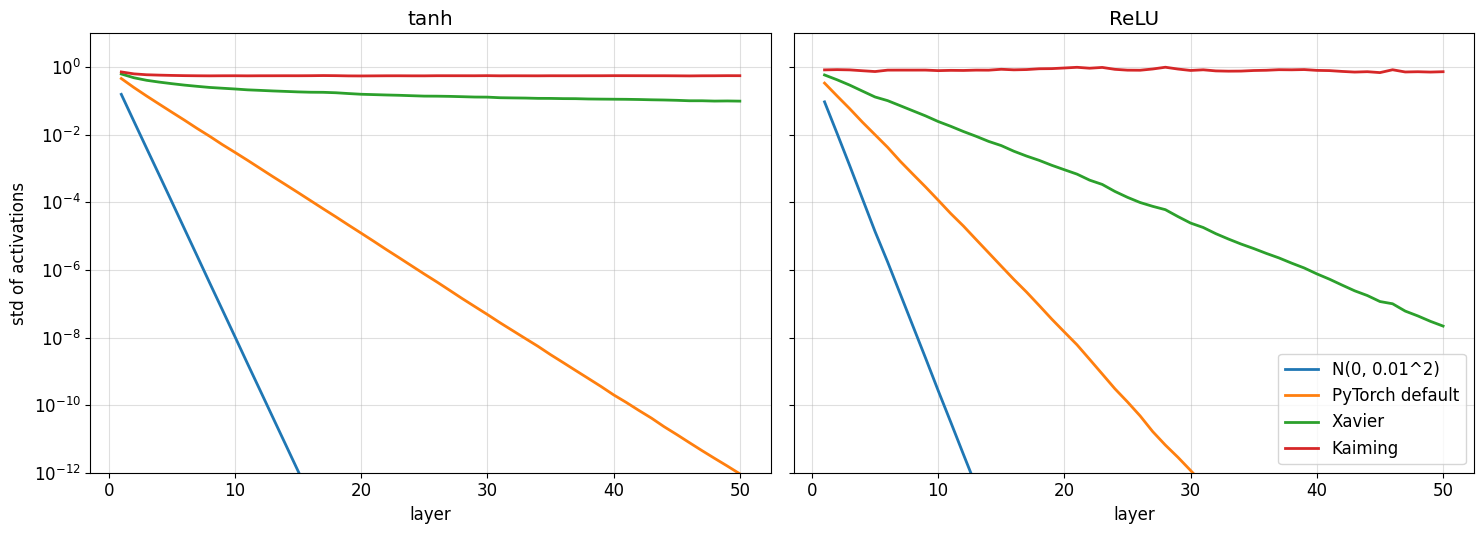

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, act_name in zip(axes, ['tanh', 'ReLU']):
    for name in INITS:
        ax.semilogy(range(1, 51), stds[name, act_name], linewidth=2, label=name)
    ax.set_title(act_name)
    ax.set_xlabel('layer')
    ax.grid(True, which='both', alpha=0.4)
axes[0].set_ylabel('std of activations')
axes[0].set_ylim(1e-12, 10)
axes[1].legend()
plt.tight_layout()
plt.show()

**Вопрос.** Какие пары (инициализация, активация) сохраняют масштаб на 50 слоях? Почему сети с инициализацией PyTorch по умолчанию всё равно обучаются (например, ResNet в задаче 4.2)?

**Ответ.** В выполненном прогоне Kaiming+ReLU сохраняет порядок масштаба: std 0.830→0.732, last/first=0.882. Kaiming+tanh тоже сохраняет ненулевой масштаб: 0.721→0.558 (отношение 0.774), но устойчивый масштаб не означает отсутствие насыщения tanh или хороших градиентов. Xavier+tanh уменьшает std с 0.628 до 0.099 (отношение 0.157); Xavier+ReLU и обе активации с малой normal/default инициализацией затухают. Для default+ReLU средний множитель std за слой 0.410, близко к 1/√6≈0.408.

В ResNet используются BN и residual-связи: нормализация регулирует масштаб, а shortcut облегчает передачу сигнала и градиентов. Поэтому вывод для plain MLP без BN напрямую к ResNet не переносится. Один seed и фиксированная ширина ограничивают обобщение численных результатов.

In [ ]:
# Численные наблюдения по фактическому запуску
for (init_name, activation), values in stds.items():
    print(init_name, activation, 'first=', values[0], 'last=', values[-1], 'ratio=', values[-1]/values[0])


N(0, 0.01^2) tanh first= 0.15657567977905273 last= 1.5607662295649813e-40 ratio= 9.96812679828318e-40
N(0, 0.01^2) ReLU first= 0.09385789930820465 last= 0.0 ratio= 0.0
PyTorch default tanh first= 0.46012088656425476 last= 9.270164930824665e-13 ratio= 2.014723782709679e-12
PyTorch default ReLU first= 0.33724427223205566 last= 3.585059259059069e-20 ratio= 1.0630452625129278e-19
Xavier tanh first= 0.6280263662338257 last= 0.09863563627004623 ratio= 0.15705652114822577
Xavier ReLU first= 0.5866118669509888 last= 2.181625724517744e-08 ratio= 3.7190276014310806e-08
Kaiming tanh first= 0.7209967374801636 last= 0.5577986836433411 ratio= 0.7736493865323316
Kaiming ReLU first= 0.8295944929122925 last= 0.7320315837860107 ratio= 0.8823968698444622


## 3.2 `AdamW` своими руками (1.5 балла)

Шаг $t = 1, 2, \dots$; $\eta$ — learning rate, $\lambda$ — weight decay, $g_t$ — градиент:
$$
\theta \leftarrow \theta - \eta\lambda\,\theta, \qquad
m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t, \qquad
v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2,
$$
$$
\hat m_t = \frac{m_t}{1 - \beta_1^t}, \qquad \hat v_t = \frac{v_t}{1 - \beta_2^t}, \qquad
\theta \leftarrow \theta - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}.
$$
Флаг `bias_correction=False` выключает деление на $1 - \beta^t$. Гиперпараметры берутся из `group` — у разных групп параметров они могут отличаться (в `train_cifar` из задачи 4.2 weight decay не применяется к параметрам BN и bias).

**Оценивание:** код — 1.1; эксперимент — 0.1; объяснение — 0.3 балла.

In [ ]:
class MyAdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2, bias_correction=True):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, bias_correction=bias_correction)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            beta1, beta2 = group['betas']
            for p in group['params']:
                if p.grad is None:
                    continue
                g = p.grad
                if g.is_sparse:
                    raise RuntimeError('Sparse gradients не поддерживаются')
                state = self.state[p]
                if not state:
                    state.update(step=0, exp_avg=torch.zeros_like(p), exp_avg_sq=torch.zeros_like(p))
                state['step'] += 1
                t = state['step']
                m, v = state['exp_avg'], state['exp_avg_sq']
                m.mul_(beta1).add_(g, alpha=1 - beta1)
                v.mul_(beta2).addcmul_(g, g, value=1 - beta2)
                mh = m / (1 - beta1 ** t) if group['bias_correction'] else m
                vh = v / (1 - beta2 ** t) if group['bias_correction'] else v
                p.mul_(1 - group['lr'] * group['weight_decay'])
                p.addcdiv_(mh, vh.sqrt().add_(group['eps']), value=-group['lr'])


In [ ]:
def final_params(make_optimizer, steps=100):
    torch.manual_seed(0)
    model = nn.Sequential(nn.Linear(10, 32), nn.Tanh(), nn.Linear(32, 1))
    optimizer = make_optimizer(model)
    gen = torch.Generator().manual_seed(1)
    for _ in range(steps):
        x = torch.randn(64, 10, generator=gen)
        loss = F.mse_loss(model(x), x[:, :1] ** 2)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return torch.cat([p.detach().flatten() for p in model.parameters()])


def param_groups(model, wd):
    return [dict(params=[p for p in model.parameters() if p.ndim > 1], weight_decay=wd),
            dict(params=[p for p in model.parameters() if p.ndim <= 1], weight_decay=0.0, lr=3e-3)]


for kwargs in [dict(lr=1e-2), dict(lr=1e-2, weight_decay=0.1), dict(lr=3e-3, betas=(0.8, 0.9), eps=1e-1)]:
    mine = final_params(lambda m: MyAdamW(m.parameters(), **kwargs))
    ref = final_params(lambda m: torch.optim.AdamW(m.parameters(), **kwargs))
    assert torch.allclose(mine, ref, atol=1e-5), kwargs
mine = final_params(lambda m: MyAdamW(param_groups(m, 0.1), lr=1e-2))
ref = final_params(lambda m: torch.optim.AdamW(param_groups(m, 0.1), lr=1e-2))
assert torch.allclose(mine, ref, atol=1e-5)

Длина шага при постоянном градиенте $g = 1$:

In [ ]:
def step_lengths(make_optimizer, steps=1000):
    p = torch.zeros(1, requires_grad=True)
    optimizer = make_optimizer([p])
    lengths = []
    for _ in range(steps):
        before = p.item()
        optimizer.zero_grad()
        p.sum().backward()
        optimizer.step()
        lengths.append(before - p.item())
    return np.array(lengths)


lr = 0.01
bc_runs = {bc: step_lengths(lambda ps: MyAdamW(ps, lr=lr, weight_decay=0, bias_correction=bc)) for bc in [True, False]}
for bc, lengths in bc_runs.items():
    ratio = np.round(lengths / lr, 4)
    print(f'bias_correction={bc!s:<5}  step / lr: ' + '  '.join(f't={t}: {ratio[t - 1]:.2f}' for t in [1, 10, 100, 1000])
          + f'   max {ratio.max():.2f} at t={ratio.argmax() + 1}')

bias_correction=True   step / lr: t=1: 1.00  t=10: 1.00  t=100: 1.00  t=1000: 1.00   max 1.00 at t=1
bias_correction=False  step / lr: t=1: 3.16  t=10: 6.53  t=100: 3.24  t=1000: 1.26   max 6.57 at t=12


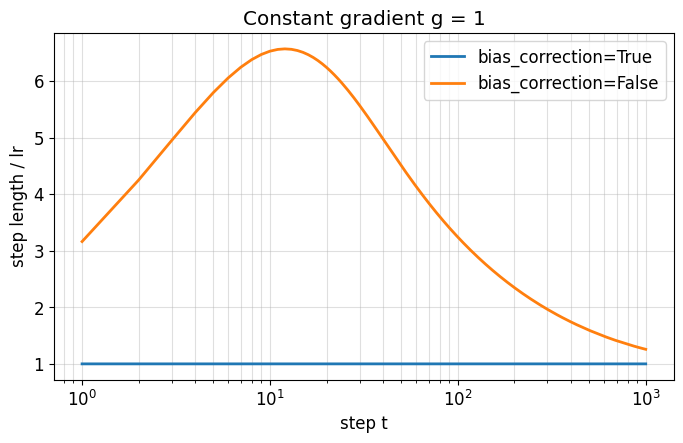

In [ ]:
plt.figure(figsize=(8, 4.5))
for bc, lengths in bc_runs.items():
    plt.semilogx(range(1, len(lengths) + 1), lengths / lr, linewidth=2, label=f'bias_correction={bc}')
plt.xlabel('step t')
plt.ylabel('step length / lr')
plt.title('Constant gradient g = 1')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Выведите длину шага без bias correction при $g_t \equiv 1$ как функцию $t$ и сравните с выводом ячейки. Чем это опасно в начале обучения?

**Ответ.** При постоянном градиенте $g_t=1$ моменты AdamW равны $m_t=1-\beta_1^t$ и $v_t=1-\beta_2^t$. Поэтому без bias correction длина шага на шаге $t$ равна

$$
\Delta_t=\eta\frac{1-\beta_1^t}{\sqrt{1-\beta_2^t}+\varepsilon}.
$$

При $\beta_1=0.9$ и $\beta_2=0.999$ первый шаг составляет примерно $3.16\eta$. Затем он растёт и достигает максимума около $6.57\eta$ на 12-м шаге — это совпадает с выводом ячейки. При увеличении $t$ множитель стремится к 1, поэтому длина шага приближается к $\eta$.

С bias correction длина шага при таком градиенте почти сразу равна $\eta$. Без этой поправки первые шаги могут быть слишком большими: параметры будут перескакивать через минимум, и обучение может стать нестабильным.

## 3.3 Cosine schedule (0.5 балла)

Множитель learning rate для `LambdaLR` (шаг $t$ считается с нуля, $T$ — число шагов, $r$ — доля от начального lr в конце):
$$
\lambda(t) = r + (1 - r)\, \frac{1 + \cos\big(\pi \min(1,\, t / T)\big)}{2}.
$$
На интервале от нулевого шага до $T$ это то же расписание, что `CosineAnnealingLR(T_max=T, eta_min=r·lr)`; после $T$ наша функция остаётся на минимуме, в отличие от продолжения cosine в PyTorch; проверка — совпадение learning rate по шагам с вашим `MyAdamW`.

**Оценивание:** код — 0.3; эксперимент — 0; объяснение — 0.2 балла.

In [ ]:
def cosine_lr(step, total_steps, min_ratio=0.0):
    if total_steps <= 0:
        raise ValueError('total_steps должен быть положительным')
    return min_ratio + (1 - min_ratio) * (1 + math.cos(math.pi * min(1, step / total_steps))) / 2


In [ ]:
T, r, base_lr = 500, 0.1, 3e-3
lam = [cosine_lr(t, T, r) for t in range(T + 1)]
assert abs(lam[0] - 1) < 1e-12 and abs(lam[T] - r) < 1e-12 and abs(cosine_lr(2 * T, T, r) - r) < 1e-12
assert abs(lam[T // 2] - (r + (1 - r) / 2)) < 1e-9


def lr_trace(make_scheduler, steps=T):
    p = torch.zeros(1, requires_grad=True)
    optimizer = MyAdamW([p], lr=base_lr)
    scheduler = make_scheduler(optimizer)
    trace = []
    for _ in range(steps):
        trace.append(scheduler.get_last_lr()[0])
        optimizer.step()
        scheduler.step()
    return np.array(trace)


mine = lr_trace(lambda opt: torch.optim.lr_scheduler.LambdaLR(opt, lambda t: cosine_lr(t, T, r)))
ref = lr_trace(lambda opt: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=T, eta_min=r * base_lr))
assert np.allclose(mine, ref, rtol=1e-6, atol=1e-12)

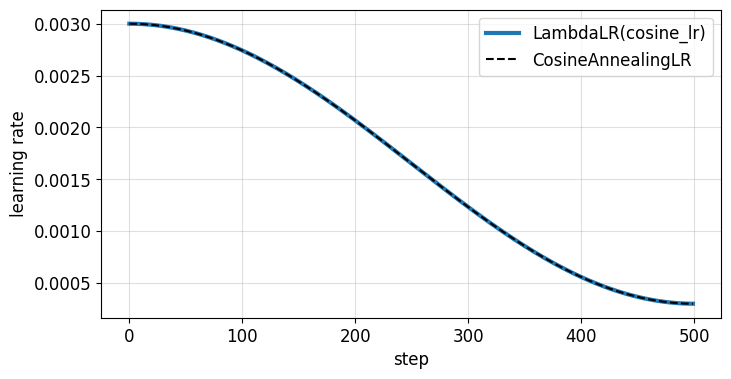

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(mine, linewidth=3, label='LambdaLR(cosine_lr)')
plt.plot(ref, 'k--', linewidth=1.5, label='CosineAnnealingLR')
plt.xlabel('step')
plt.ylabel('learning rate')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Зачем уменьшать learning rate к концу обучения, если оптимизатор и так адаптивный? Что происходит со стохастическим методом при постоянном шаге около минимума?

**Ответ.** AdamW подстраивает шаг для каждого параметра по накопленным градиентам, но общий learning rate всё равно задаёт размер обновления. Если оставить его большим к концу обучения, параметры могут перескакивать через минимум. Поэтому learning rate постепенно уменьшают: так модель делает более мелкие шаги и точнее настраивает параметры.

При постоянном шаге стохастический градиент содержит шум из-за случайного выбора объектов или батчей. Даже рядом с минимумом обновления продолжаются, поэтому параметры обычно колеблются вокруг него, а не останавливаются точно в одной точке. В невыпуклой задаче такое поведение само по себе не гарантирует нахождение глобального минимума.

---
# 4. ResNet на CIFAR-10

CIFAR-10: 50 000 + 10 000 цветных картинок $32 \times 32$, 10 классов. Весь датасет хранится одним `uint8`-тензором на `device` (≈ 180 MB), нормализация делается на лету над батчем.

In [ ]:
N_TRAIN = 10_000 if FAST_MODE else 50_000
N_TEST = 2_000 if FAST_MODE else 10_000

cifar_train = datasets.CIFAR10(DATA_ROOT, train=True, download=True)
cifar_test = datasets.CIFAR10(DATA_ROOT, train=False, download=True)
CIFAR_CLASSES = cifar_train.classes


def to_tensors(ds, n):
    X = torch.from_numpy(ds.data[:n]).permute(0, 3, 1, 2).contiguous()   # uint8 (N, 3, 32, 32)
    return X.to(device), torch.tensor(ds.targets[:n]).to(device)


X_train, Y_train = to_tensors(cifar_train, N_TRAIN)
X_test, Y_test = to_tensors(cifar_test, N_TEST)
CIFAR_MEAN = (X_train.float() / 255).mean(dim=(0, 2, 3))
CIFAR_STD = (X_train.float() / 255).std(dim=(0, 2, 3))
X_train.shape, X_test.shape, CIFAR_MEAN, CIFAR_STD

100%|██████████| 170M/170M [22:21<00:00, 127kB/s]


(torch.Size([50000, 3, 32, 32]),
 torch.Size([10000, 3, 32, 32]),
 tensor([0.4914, 0.4822, 0.4465], device='cuda:0'),
 tensor([0.2470, 0.2435, 0.2616], device='cuda:0'))

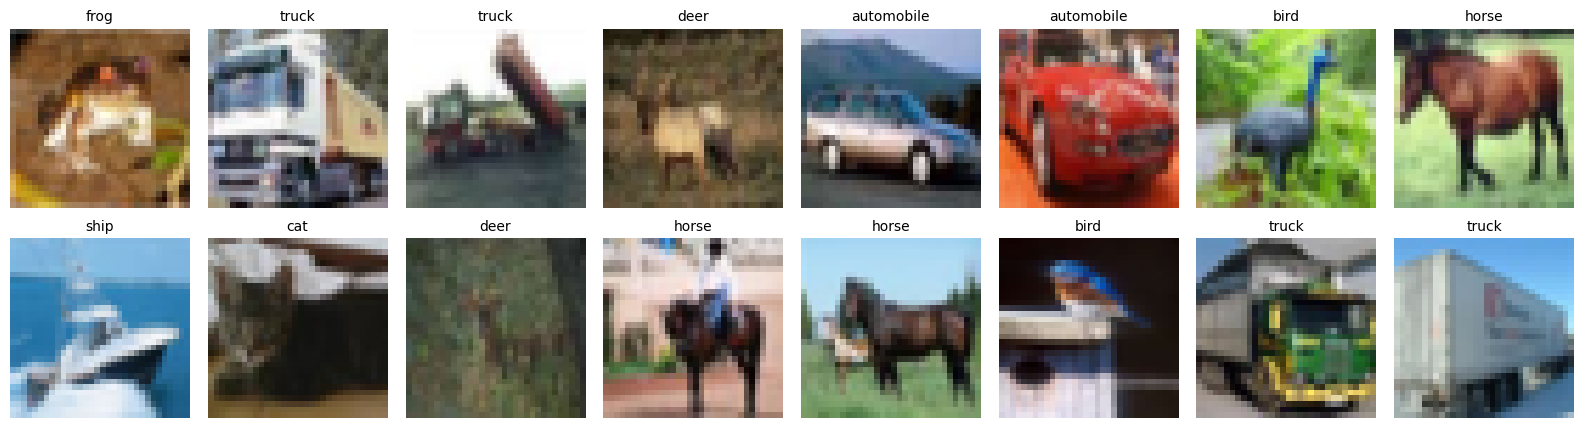

In [ ]:
def normalize(x_uint8):
    return (x_uint8.float() / 255 - CIFAR_MEAN[:, None, None]) / CIFAR_STD[:, None, None]


fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(X_train[i].permute(1, 2, 0).cpu())
    ax.set_title(CIFAR_CLASSES[Y_train[i]], fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4.1 ResNet для CIFAR (1 балл)

ResNet для CIFAR из §4.2 статьи [Deep Residual Learning for Image Recognition](https://arxiv.org/pdf/1512.03385), He et al., 2015: stem — свёртка $3 \times 3$ на 16 каналов с BN и ReLU; затем три стадии по $n$ блоков шириной 16, 32 и 64; в конце global average pooling и `Linear(64, 10)`. Глубина $6n + 2$. Первый блок второй и третьей стадии — со stride 2.

Блок (свёртки $3 \times 3$ без bias):
$$
F(x) = \mathrm{BN}\Big(\mathrm{Conv}\big(\mathrm{ReLU}(\mathrm{BN}(\mathrm{Conv}(x)))\big)\Big), \qquad y = \mathrm{ReLU}\big(F(x) + \mathrm{shortcut}(x)\big).
$$
Shortcut — `Identity`, а при смене формы (stride 2 или другое число каналов) — свёртка $1 \times 1$ с тем же stride и BN после неё. Флаги:

- `residual=False` — plain-сеть: сложения нет, shortcut-модулей нет;
- `separable=True` — каждая $3 \times 3$ свёртка блоков заменена на depthwise $3 \times 3$ и следующую за ней pointwise $1 \times 1$, обе без bias; stem остаётся обычным.

**Оценивание:** код — 1; эксперимент — 0; объяснение — 0 балла.

In [ ]:
def conv3x3(c_in, c_out, stride=1, separable=False):
    if separable:
        return nn.Sequential(nn.Conv2d(c_in, c_in, 3, stride, 1, groups=c_in, bias=False),
                             nn.Conv2d(c_in, c_out, 1, bias=False))
    return nn.Conv2d(c_in, c_out, 3, stride, 1, bias=False)


class Block(nn.Module):
    def __init__(self, c_in, c_out, stride=1, residual=True, separable=False):
        super().__init__()
        self.residual = residual
        self.branch = nn.Sequential(conv3x3(c_in, c_out, stride, separable), nn.BatchNorm2d(c_out),
                                    nn.ReLU(), conv3x3(c_out, c_out, separable=separable), nn.BatchNorm2d(c_out))
        if residual:
            self.shortcut = (nn.Identity() if stride == 1 and c_in == c_out else
                             nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride, bias=False), nn.BatchNorm2d(c_out)))

    def forward(self, x):
        out = self.branch(x)
        if self.residual:
            out = out + self.shortcut(x)
        return F.relu(out)


class ResNetCIFAR(nn.Module):
    def __init__(self, depth=20, residual=True, separable=False, widths=(16, 32, 64), n_classes=10):
        super().__init__()
        assert (depth - 2) % 6 == 0
        n = (depth - 2) // 6
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, padding=1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU())
        blocks, c_in = [], widths[0]
        for stage, c_out in enumerate(widths):
            for j in range(n):
                stride = 2 if stage > 0 and j == 0 else 1
                blocks.append(Block(c_in, c_out, stride, residual, separable))
                c_in = c_out
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(widths[-1], n_classes)

    def forward(self, x):
        return self.fc(self.blocks(self.stem(x)).mean((2, 3)))


In [ ]:
x = torch.randn(2, 3, 32, 32)
for depth in [8, 20, 56]:
    for kwargs in [dict(), dict(residual=False), dict(separable=True)]:
        assert ResNetCIFAR(depth, **kwargs)(x).shape == (2, 10), (depth, kwargs)
assert n_params(ResNetCIFAR(20)) == 272_474
assert n_params(ResNetCIFAR(20, residual=False)) == 269_722
{name: n_params(ResNetCIFAR(depth, **kwargs)) for name, depth, kwargs in
 [('ResNet-20', 20, {}), ('ResNet-56', 56, {}), ('ResNet-20, separable', 20, dict(separable=True))]}

{'ResNet-20': 272474, 'ResNet-56': 855770, 'ResNet-20, separable': 40522}

## 4.2 Обучение (2 балла)

Реализуйте `train_cifar`: `MyAdamW` из 3.2 (weight decay только для параметров с `ndim > 1`), `LambdaLR` с `cosine_lr` из 3.3 до нуля за всё обучение ($r = 0$), cross-entropy, батч 256. После каждой эпохи — test accuracy. Вернуть историю `dict(train_loss, test_acc)` по эпохам.

Для ResNet-20 при `FAST_MODE = False` ориентир test accuracy — `TARGET_ACC` за `EPOCHS` эпох с `LR`. Это диагностический ориентир, не жёсткий порог балла: при заметном отставании проверьте normalisation, train/eval, scheduler и loss и опишите результат. Аугментации в этом протоколе нет. Каждый батч нормируйте через `normalize`; `scheduler.step()` вызывается после каждого `optimizer.step()`, `train_loss` — среднее по объектам за эпоху.

Test используется для учебных кривых с заранее фиксированными гиперпараметрами. Если выбираете гиперпараметры самостоятельно, выделите validation из train; test не используйте для выбора конфигурации.

**Оценивание:** код — 1.1; эксперимент — 0.6; объяснение — 0.3 балла.

In [ ]:
EPOCHS = 3 if FAST_MODE else 20
LR = 0.003
TARGET_ACC = 0.82


def train_cifar(model, epochs, lr, weight_decay=0.05, batch_size=256, log=True):
    model = model.to(device)
    history = dict(train_loss=[], test_acc=[])
    start = time.time()
    groups = [dict(params=[p for p in model.parameters() if p.ndim > 1], weight_decay=weight_decay),
              dict(params=[p for p in model.parameters() if p.ndim <= 1], weight_decay=0.0)]
    optimizer = MyAdamW(groups, lr=lr)
    total_steps = epochs * math.ceil(len(X_train) / batch_size)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda t: cosine_lr(t, total_steps))
    for epoch in range(epochs):
        model.train()
        loss_sum = 0.0
        for x, y in iterate_batches(X_train, Y_train, batch_size, transform=normalize):
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(x), y)
            loss.backward()
            optimizer.step()
            scheduler.step()
            loss_sum += loss.item() * len(y)
        history['train_loss'].append(loss_sum / len(X_train))
        history['test_acc'].append(accuracy(predict_logits(model, X_test, batch_size=batch_size, transform=normalize), Y_test))
        if log:
            print(f"epoch {epoch + 1}/{epochs}: loss={history['train_loss'][-1]:.4f}, test={history['test_acc'][-1]:.4f}, seconds={time.time()-start:.1f}")
    return history


In [ ]:
set_seed(0)
resnet20 = ResNetCIFAR(20)
started = time.perf_counter()
history = train_cifar(resnet20, EPOCHS, LR)
RUN_TIMES['cifar_resnet20_seconds'] = time.perf_counter() - started
history_cifar = history
test_acc = history['test_acc'][-1]
train_acc = accuracy(predict_logits(resnet20, X_train[:10_000], transform=normalize), Y_train[:10_000])
if not FAST_MODE and test_acc < TARGET_ACC:
    print(f'Accuracy {test_acc:.3f} ниже ориентира {TARGET_ACC:.2f}: проверьте протокол и обсудите результат.')
{'train acc': train_acc, 'test acc': test_acc}

epoch 1/20: loss=1.4345, test=0.4880, seconds=17.4
epoch 2/20: loss=0.9686, test=0.6126, seconds=32.7
epoch 3/20: loss=0.7669, test=0.6692, seconds=48.1
epoch 4/20: loss=0.6418, test=0.7252, seconds=63.7
epoch 5/20: loss=0.5606, test=0.7317, seconds=79.5
epoch 6/20: loss=0.4919, test=0.7745, seconds=95.5
epoch 7/20: loss=0.4296, test=0.7577, seconds=111.8
epoch 8/20: loss=0.3733, test=0.7867, seconds=128.2
epoch 9/20: loss=0.3179, test=0.7971, seconds=144.8
epoch 10/20: loss=0.2678, test=0.8051, seconds=161.5
epoch 11/20: loss=0.2117, test=0.8015, seconds=178.4
epoch 12/20: loss=0.1572, test=0.8198, seconds=195.4
epoch 13/20: loss=0.1090, test=0.8207, seconds=212.6
epoch 14/20: loss=0.0694, test=0.8244, seconds=229.8
epoch 15/20: loss=0.0411, test=0.8302, seconds=247.2
epoch 16/20: loss=0.0254, test=0.8294, seconds=264.6
epoch 17/20: loss=0.0170, test=0.8300, seconds=282.2
epoch 18/20: loss=0.0141, test=0.8302, seconds=299.7
epoch 19/20: loss=0.0117, test=0.8299, seconds=317.1
epoch 20

{'train acc': 0.9996999502182007, 'test acc': 0.8305000066757202}

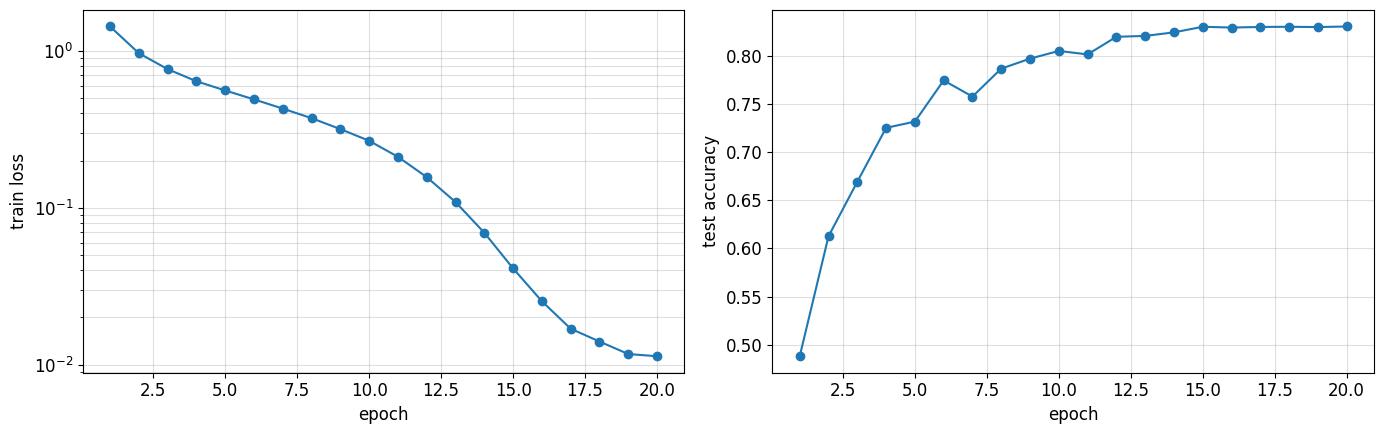

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
epochs_axis = range(1, len(history['test_acc']) + 1)
ax1.semilogy(epochs_axis, history['train_loss'], 'o-')
ax1.set_ylabel('train loss')
ax2.plot(epochs_axis, history['test_acc'], 'o-')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
plt.tight_layout()
plt.show()

**Вопрос.** Какой разрыв между train и test accuracy в конце обучения? Как ведут себя train loss и test accuracy на последних эпохах, когда learning rate уходит к нулю?

**Ответ.** После 20 эпох точность на обучающих данных составила 99,97%, на тестовых — 83,05%. Разрыв равен 16,92 процентного пункта. Ориентир в 82% достигнут, но большой разрыв показывает, что модель почти запомнила обучающую выборку и хуже обобщает на новые данные.

На последних трёх эпохах train loss продолжал снижаться: 0,01406 → 0,01170 → 0,01132. Test accuracy немного колебалась: 83,02% → 82,99% → 83,05%. По мере уменьшения learning rate модель делала меньшие шаги, а качество на тестовой выборке оставалось примерно на одном уровне. В этом прогоне лучший результат получился на последней эпохе. На более ранних эпохах test accuracy тоже менялась неравномерно. Гиперпараметры и число эпох были заданы условием, а test accuracy использовалась для оценки, а не для подбора настроек.

In [ ]:
# Численные наблюдения по фактическому запуску
print(f'train={train_acc:.4f}, test={test_acc:.4f}, gap={100*(train_acc-test_acc):.2f} п.п.')
print('Последние loss:', history_cifar['train_loss'][-3:])
print('Последние test accuracy:', history_cifar['test_acc'][-3:])


train=0.9997, test=0.8305, gap=16.92 п.п.
Последние loss: [0.014058901065587997, 0.011697098894715308, 0.011323999177217483]
Последние test accuracy: [0.8301999568939209, 0.8298999667167664, 0.8305000066757202]


## 4.3 Абляции (1.5 балла)

Сравните **plain-20 и plain-56** при одинаковых `ABL_EPOCHS` и `LR`. Это два дополнительных обучения. Результат — `ablation[name] = dict(params, train_acc, test_acc, minutes, history)`, где `train_acc` считается на первых 10 000 объектах train, а `history` возвращается `train_cifar`.

Перед каждой конфигурацией вызовите `set_seed(0)`. Проверяем гипотезу: увеличение глубины plain-сети может затруднить оптимизацию даже на train ([He et al., 2015](https://arxiv.org/pdf/1512.03385)). Это не обещание, что при данном optimizer и коротком бюджете эффект обязательно появится. Отличайте результат «хуже на train» от «лучше на train, хуже на test». Для сравнения с residual-сетями нужен одинаковый протокол; основной ResNet-20 обучался дольше, его финальную accuracy нельзя напрямую трактовать как контроль этого опыта.

**Оценивание:** код — 0.2; эксперимент — 0.7; объяснение — 0.6 балла.

In [ ]:
ABL_EPOCHS = 2 if FAST_MODE else 10
ABLATIONS = {
    'plain-20': dict(depth=20, residual=False),
    'plain-56': dict(depth=56, residual=False),
}

In [ ]:
ablation = {}
for name, config in ABLATIONS.items():
    set_seed(0)
    model = ResNetCIFAR(**config)
    started = time.perf_counter()
    hist = train_cifar(model, ABL_EPOCHS, LR)
    ablation[name] = dict(params=n_params(model),
                          train_acc=accuracy(predict_logits(model, X_train[:10_000], batch_size=256, transform=normalize), Y_train[:10_000]),
                          test_acc=hist['test_acc'][-1], minutes=(time.perf_counter() - started) / 60, history=hist)
    del model

print(f'{"model":<22}{"params":>9}{"train acc":>11}{"test acc":>10}{"minutes":>9}')
for name, res in ablation.items():
    print(f'{name:<22}{res["params"]:>9,}{res["train_acc"]:>11.4f}{res["test_acc"]:>10.4f}{res["minutes"]:>9.1f}')


epoch 1/10: loss=1.7175, test=0.2539, seconds=16.6
epoch 2/10: loss=1.3458, test=0.4200, seconds=33.3
epoch 3/10: loss=1.0780, test=0.5896, seconds=50.1
epoch 4/10: loss=0.9012, test=0.6716, seconds=67.0
epoch 5/10: loss=0.7825, test=0.7268, seconds=83.9
epoch 6/10: loss=0.6783, test=0.7292, seconds=100.7
epoch 7/10: loss=0.5914, test=0.7657, seconds=117.6
epoch 8/10: loss=0.5245, test=0.7857, seconds=134.5
epoch 9/10: loss=0.4706, test=0.7919, seconds=151.4
epoch 10/10: loss=0.4431, test=0.7932, seconds=168.3
epoch 1/10: loss=2.0043, test=0.2099, seconds=51.8
epoch 2/10: loss=1.8070, test=0.2592, seconds=103.4
epoch 3/10: loss=1.6979, test=0.3644, seconds=155.1
epoch 4/10: loss=1.6123, test=0.3279, seconds=207.8
epoch 5/10: loss=1.5096, test=0.3919, seconds=263.3
epoch 6/10: loss=1.4006, test=0.4499, seconds=318.0
epoch 7/10: loss=1.2914, test=0.5341, seconds=373.0
epoch 8/10: loss=1.1867, test=0.5568, seconds=428.2
epoch 9/10: loss=1.1046, test=0.5830, seconds=483.4
epoch 10/10: loss

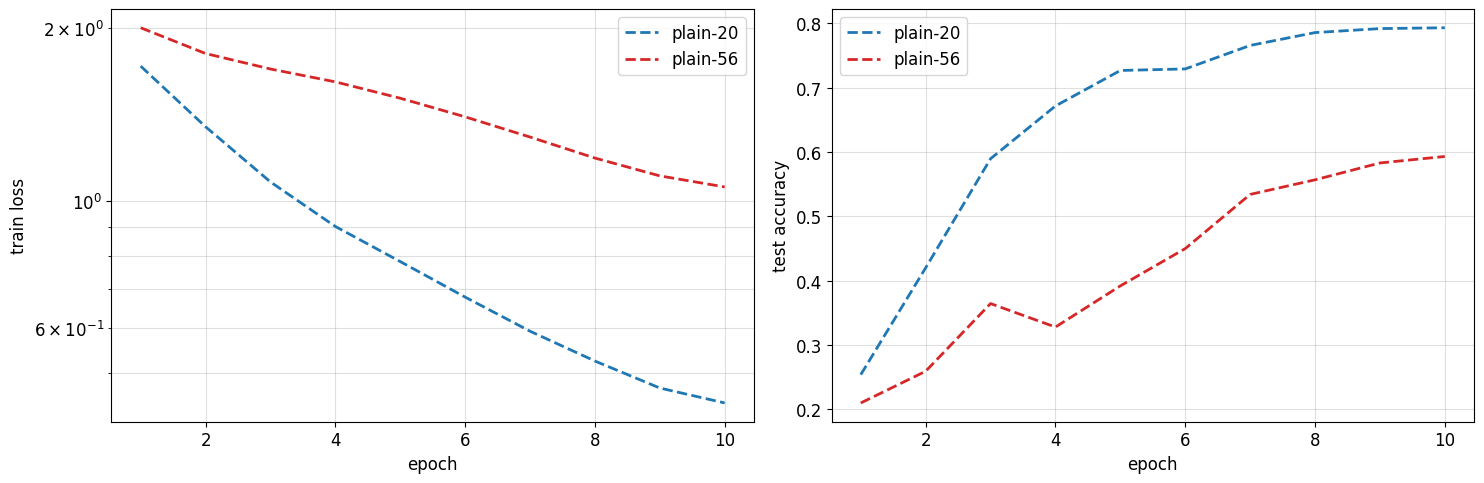

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
for name in ABLATIONS:
    hist = ablation[name]['history']
    style = '-' if name.startswith('ResNet') else '--'
    color = 'tab:blue' if '20' in name else 'tab:red'
    epochs_axis = range(1, len(hist['train_loss']) + 1)
    ax1.semilogy(epochs_axis, hist['train_loss'], style, color=color, linewidth=2, label=name)
    ax2.plot(epochs_axis, hist['test_acc'], style, color=color, linewidth=2, label=name)
ax1.set_ylabel('train loss')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
    ax.legend()
plt.tight_layout()
plt.show()

**Вопрос.** Есть ли в вашем прогоне ухудшение train loss при увеличении глубины? Как изменились train и test accuracy? Какие наблюдения говорят о трудностях оптимизации, а какие — о переобучении? Если ухудшения на train нет, напишите это. Предложите **один** следующий контрольный эксперимент, позволяющий проверить ваше объяснение; запускать его не требуется.

**Ответ.** При одинаковом обучении на 10 эпохах plain-20 получила train loss 0,4431, точность на обучающих данных 85,30% и на тестовых — 79,32%. У plain-56 train loss оказался выше — 1,0565, а точность ниже: 62,64% на обучающей и 59,31% на тестовой выборке. Значит, при увеличении глубины качество ухудшилось и на обучающих данных: train loss вырос на 0,6134, train accuracy снизилась на 22,66 п.п., test accuracy — на 20,01 п.п.

Поскольку глубокая сеть хуже справилась уже с обучающей выборкой, результат скорее указывает на трудности оптимизации при выбранных настройках и ограничении в 10 эпох, чем на переобучение. Разрыв между train и test accuracy составил 5,98 п.п. у plain-20 и 3,33 п.п. у plain-56. Меньший разрыв у plain-56 не означает, что она лучше обобщает: её точность ниже на обеих выборках.

Чтобы проверить роль residual-связей, можно сравнить plain-56 и residual-56 при одинаковых данных, seed, learning rate и числе эпох. Результат одного короткого прогона не позволяет сделать общий вывод о влиянии глубины.

In [ ]:
# Численные наблюдения по фактическому запуску
a, b = ablation['plain-20'], ablation['plain-56']
print('Δ plain56−plain20:', {k: b[k]-a[k] for k in ['train_acc','test_acc']})
print('Δ train loss:', b['history']['train_loss'][-1]-a['history']['train_loss'][-1])
print('У глубокой сети выше train loss:', b['history']['train_loss'][-1] > a['history']['train_loss'][-1])


Δ plain56−plain20: {'train_acc': -0.22659999132156372, 'test_acc': -0.20009994506835938}
Δ train loss: 0.6134100791168213
У глубокой сети выше train loss: True


---
# 5. Атаки

Модель — маленькая CNN на FashionMNIST (пиксели в $[0, 1]$, без `Normalize`). В финальном режиме модель учится на полном train, а серии атак идут по фиксированным 1000 test-объектам. Раздел 5.1 обязателен; далее выполняется только ветка, выбранная в `ATTACK_TRACK`. Все модели во время оценки атак находятся в `eval()`. Метрики на такой подвыборке имеют sampling noise; близкие результаты не следует ранжировать как надёжное преимущество.

In [ ]:
N_FM_TRAIN = 12_000 if FAST_MODE else 60_000
N_FM_TEST = 256 if FAST_MODE else 1_000
FM_EPOCHS = 2 if FAST_MODE else 5

fm_train = datasets.FashionMNIST(DATA_ROOT, train=True, download=True)
fm_test = datasets.FashionMNIST(DATA_ROOT, train=False, download=True)
FM_CLASSES = fm_train.classes


def fm_tensors(ds, n):
    return (ds.data[:n, None].float() / 255).to(device), ds.targets[:n].to(device)


XF_train, YF_train = fm_tensors(fm_train, N_FM_TRAIN)
XF_test, YF_test = fm_tensors(fm_test, N_FM_TEST)
XF_train.shape, XF_test.shape

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 171kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.06MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 21.9MB/s]


(torch.Size([60000, 1, 28, 28]), torch.Size([1000, 1, 28, 28]))

Модель, обучение и атаки FGSM и PGD в $L_\infty$ — готовый код:

In [ ]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Linear(64 * 7 * 7, n_classes)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


def train_fm(model, epochs=FM_EPOCHS, lr=1e-3):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        model.train()
        for x, y in iterate_batches(XF_train, YF_train, 128):
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    return model

In [ ]:
def fgsm_attack(model, x, y, eps):
    x = x.detach()
    x_adv = x.clone().requires_grad_(True)
    with torch.enable_grad():
        grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
    return (x + eps * grad.sign()).clamp(0, 1).detach()


def pgd_attack(model, x, y, eps, alpha, steps, random_start=True):
    x = x.detach()
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1) if random_start else x.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
    return x_adv.detach()


def pgd(model, x, y, eps, steps=20):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / steps, steps=steps)


def attack_accuracy(model, X, Y, attack=None, batch_size=500, **attack_kwargs):
    model.eval()
    correct = 0
    for i in range(0, len(X), batch_size):
        x, y = X[i:i + batch_size], Y[i:i + batch_size]
        if attack is not None:
            x = attack(model, x, y, **attack_kwargs)
        with torch.no_grad():
            correct += (model(x).argmax(dim=1) == y).sum().item()
    return correct / len(X)


def assert_no_param_grads(model):
    assert all(p.grad is None for p in model.parameters())

In [ ]:
set_seed(0)
started = time.perf_counter()
model_a = train_fm(SmallCNN())
RUN_TIMES['fashion_standard_seconds'] = time.perf_counter() - started
model_a.zero_grad(set_to_none=True)
{'clean': attack_accuracy(model_a, XF_test, YF_test),
 'FGSM, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, fgsm_attack, eps=0.1),
 'PGD-20, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)}

{'clean': 0.916, 'FGSM, eps=0.1': 0.073, 'PGD-20, eps=0.1': 0.007}

## 5.1 PGD в $L_2$ (1 балл)

Ограничение $\|\delta\|_2 \le \varepsilon$. Линеаризация loss (как при выводе FGSM) даёт шаг по нормированному градиенту, а проекция на шар — масштабирование:
$$
x' = x^{(k)} + \alpha\, \frac{g}{\|g\|_2}, \qquad
\delta = x' - x, \qquad
x^{(k+1)} = \mathrm{clip}_{[0, 1]}\Big(x + \delta \cdot \min\big(1,\, \tfrac{\varepsilon}{\|\delta\|_2}\big)\Big).
$$
Нормы — по каждой картинке отдельно. Старт из $x$ (без random start).

**Оценивание:** код — 0.6; эксперимент — 0.2; объяснение — 0.2 балла.

In [ ]:
def pgd_l2(model, x, y, eps, alpha, steps):
    x = x.detach()
    adv = x.clone()
    shape = (-1,) + (1,) * (x.ndim - 1)
    for _ in range(steps):
        adv.requires_grad_(True)
        with torch.enable_grad():
            g, = torch.autograd.grad(F.cross_entropy(model(adv), y), adv)
        direction = g / g.flatten(1).norm(dim=1).clamp_min(1e-12).view(shape)
        delta = adv.detach() + alpha * direction - x
        scale = (eps / delta.flatten(1).norm(dim=1).clamp_min(1e-12)).clamp(max=1)
        adv = (x + delta * scale.view(shape)).clamp(0, 1).detach()
    return adv


In [ ]:
x, y = XF_test[:500], YF_test[:500]
eps2 = 2.0
x_adv = pgd_l2(model_a, x, y, eps=eps2, alpha=2.5 * eps2 / 20, steps=20)
assert (x_adv - x).flatten(1).norm(dim=1).max() <= eps2 + 1e-4
assert x_adv.min() >= 0 and x_adv.max() <= 1 and not x_adv.requires_grad
assert_no_param_grads(model_a)
acc_clean, acc_l2 = attack_accuracy(model_a, x, y), attack_accuracy(model_a, x_adv, y)
print(f'Падение accuracy под PGD-L2: {acc_clean - acc_l2:.3f}; маленькое падение требует диагностики.')
acc_clean, acc_l2

Падение accuracy под PGD-L2: 0.920; маленькое падение требует диагностики.


(0.92, 0.0)

In [ ]:
def pgd_l2_20(model, x, y, eps):
    return pgd_l2(model, x, y, eps, alpha=2.5 * eps / 20, steps=20)


eps_l2 = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
acc_l2 = [attack_accuracy(model_a, XF_test, YF_test, pgd_l2_20, eps=e) for e in eps_l2]
acc_linf = attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)
dict(zip(eps_l2, acc_l2)), acc_linf

({0.0: 0.916, 0.5: 0.445, 1.0: 0.082, 1.5: 0.01, 2.0: 0.0, 3.0: 0.0, 4.0: 0.0},
 0.006)

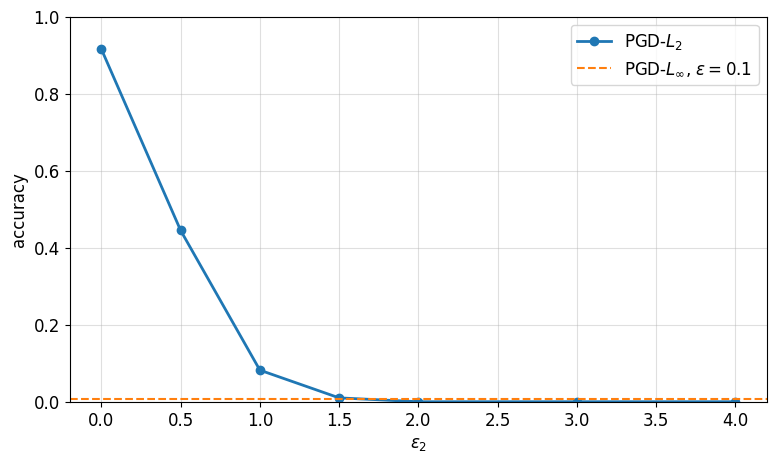

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(eps_l2, acc_l2, 'o-', linewidth=2, label=r'PGD-$L_2$')
plt.axhline(acc_linf, color='tab:orange', linestyle='--', label=r'PGD-$L_\infty$, $\varepsilon = 0.1$')
plt.xlabel(r'$\varepsilon_2$')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

Возмущения обеих атак на одних картинках; $\varepsilon_2$ — ближайшая по accuracy точка проверенной сетки. Если разница велика, сравнение не следует называть сравнением при равной силе атаки. Цветовая шкала каждой карты нормирована отдельно; абсолютные нормы выведены под рисунком:

а рисунке показаны возмущения обеих атак для одних и тех же изображений. Для PGD-L₂ выбрано значение ε₂, при котором accuracy ближе всего к результату PGD-L∞. Если точности заметно различаются, атаки нельзя считать одинаковыми по силе. Цвета на картах нормированы отдельно, поэтому сравнивать их яркость напрямую нельзя. Абсолютные нормы возмущений указаны под рисунком.

Ближайшая точка сетки: eps2=1.5, accuracy gap=0.004


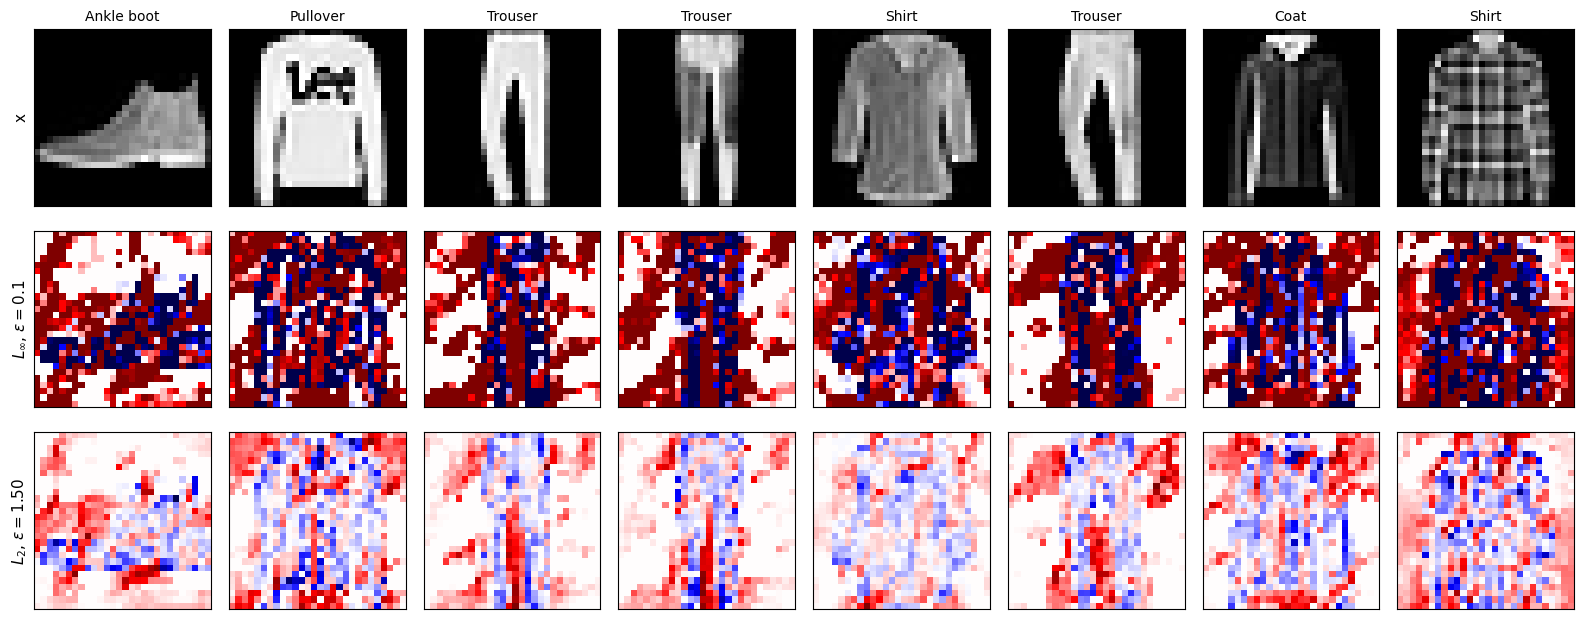

$L_\infty$, $\varepsilon=0.1$ L_inf = 0.100   L_2 = 2.109
$L_2$, $\varepsilon=1.50$    L_inf = 0.250   L_2 = 1.492


In [ ]:
# Поиск ближайшей проверенной точки не предполагает монотонность конечной PGD.
match_idx = int(np.argmin(np.abs(np.asarray(acc_l2) - acc_linf)))
eps2_match = float(eps_l2[match_idx])
print(f'Ближайшая точка сетки: eps2={eps2_match}, accuracy gap={abs(acc_l2[match_idx] - acc_linf):.3f}')
x8, y8 = XF_test[:8], YF_test[:8]
torch.manual_seed(0)
deltas = {r'$L_\infty$, $\varepsilon=0.1$': pgd(model_a, x8, y8, 0.1) - x8,
          rf'$L_2$, $\varepsilon={eps2_match:.2f}$': pgd_l2_20(model_a, x8, y8, eps2_match) - x8}
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for i in range(8):
    axes[0, i].imshow(x8[i, 0].cpu(), cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(FM_CLASSES[y8[i]], fontsize=10)
    for row, d in enumerate(deltas.values(), start=1):
        vmax = d[i].abs().max().item()
        axes[row, i].imshow(d[i, 0].cpu(), cmap='seismic', vmin=-vmax, vmax=vmax)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
for ax, label in zip(axes[:, 0], ['x'] + list(deltas)):
    ax.set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()
for name, d in deltas.items():
    print(f'{name:<28} L_inf = {d.abs().amax(dim=(1, 2, 3)).mean():.3f}   L_2 = {d.flatten(1).norm(dim=1).mean():.3f}')

**Вопрос.** Какая точка сетки $\varepsilon_2$ ближе всего по accuracy к $L_\infty$-атаке с $\varepsilon = 0.1$ и как велик остаточный разрыв? Какова $L_2$-норма самого $L_\infty$-возмущения? Где сосредоточено $L_2$-возмущение на ваших изображениях и как это связано с нормированным градиентом?

**Ответ.** Ближе всего по accuracy оказалась точка ε₂ = 1,5: после PGD-L₂ accuracy составила 1,0%, а после PGD-L∞ с ε = 0,1 — 0,6%. Разница — 0,4 процентного пункта, или 4 объекта из 1000. Результаты близки на этой выборке, но это не означает, что атаки одинаково сильны в целом.

На восьми изображениях средняя L₂-норма возмущения PGD-L∞ составила 2,109 (от 1,951 до 2,262), а PGD-L₂ — 1,492. При этом у PGD-L₂ среднее максимальное изменение одного пикселя было 0,250 против 0,100 у PGD-L∞.

На показанных картах L₂-возмущение сильнее заметно на отдельных участках одежды, например по нижним краям и между штанинами; изменения видны и на фоне. Это связано с тем, что L₂-атака направляет шаг по нормированному градиенту: пиксели с большими компонентами градиента получают более сильное изменение. У L∞-атаки sign градиента задаёт одинаковый размер шага для пикселей до проекции. Цветовые шкалы нормированы отдельно, поэтому силу возмущений лучше сравнивать по указанным нормам.

In [ ]:
# Численные наблюдения по фактическому запуску
print('eps2=', eps2_match, 'accuracy gap=', abs(acc_l2[match_idx]-acc_linf))
for name, delta in deltas.items():
    print(name, 'L2 по изображениям:', delta.flatten(1).norm(dim=1).cpu().tolist())


eps2= 1.5 accuracy gap= 0.004
$L_\infty$, $\varepsilon=0.1$ L2 по изображениям: [1.9512795209884644, 2.2616066932678223, 2.0167481899261475, 2.0334970951080322, 2.11706805229187, 2.0577359199523926, 2.172015428543091, 2.2622992992401123]
$L_2$, $\varepsilon=1.50$ L2 по изображениям: [1.4925421476364136, 1.4917792081832886, 1.4931221008300781, 1.490403175354004, 1.495452880859375, 1.4918156862258911, 1.486710786819458, 1.493284821510315]


## 5.2 Targeted attack (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'targeted'`. Ветку 5.3 при этом можно оставить пустой.

Цель — не просто ошибка, а заданный класс $t$: минимизируем loss по целевой метке
$$
x^{(k+1)} = \Pi_{B_\infty(x, \varepsilon)}\Big[x^{(k)} - \alpha\, \mathrm{sign}\, \nabla_x L\big(f(x^{(k)}), t\big)\Big].
$$

1. Реализуйте `pgd_targeted` ($L_\infty$, random start, как `pgd_attack`).
2. Реализуйте `targeted_success_matrix`: $S[s, t]$ — доля всех картинок класса $s$, которые после атаки с целью $t$ классифицируются как $t$, включая изначально ошибочные. Верните CPU-тензор; диагональ и строки отсутствующих классов — `nan`. Обрабатывайте вход батчами не более 128 объектов, сигнатуру менять не нужно. Сопоставьте результат с готовой clean confusion matrix ниже.

**Оценивание:** код — 1; эксперимент — 0.4; объяснение — 0.6 балла.

In [ ]:
if ATTACK_TRACK == 'targeted':
    def pgd_targeted(model, x, target, eps, alpha, steps):
        x = x.detach()
        adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1)
        for _ in range(steps):
            adv.requires_grad_(True)
            with torch.enable_grad():
                g, = torch.autograd.grad(F.cross_entropy(model(adv), target), adv)
            adv = adv.detach() - alpha * g.sign()
            adv = torch.clamp(adv, min=x - eps, max=x + eps).clamp(0, 1).detach()
        return adv.detach()


    def targeted_success_matrix(model, x, y, eps, steps=20, n_classes=10):
        model.eval()
        result = torch.full((n_classes, n_classes), float('nan'))
        for source in range(n_classes):
            xs = x[y == source]
            if len(xs) == 0:
                continue
            for target in range(n_classes):
                if target == source:
                    continue
                hits = 0
                for start in range(0, len(xs), 128):
                    batch = xs[start:start + 128]
                    targets = torch.full((len(batch),), target, dtype=torch.long, device=x.device)
                    adv = pgd_targeted(model, batch, targets, eps, 2.5 * eps / max(steps, 1), steps)
                    with torch.no_grad():
                        hits += (model(adv).argmax(1) == targets).sum().item()
                result[source, target] = hits / len(xs)
        return result


In [ ]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    x, y = XF_test[:1000], YF_test[:1000]
    target = (y + 1) % 10
    x_t = pgd_targeted(model_a, x, target, eps=0.1, alpha=0.0125, steps=20)
    assert (x_t - x).abs().max() <= 0.1 + 1e-6 and x_t.min() >= 0 and x_t.max() <= 1
    assert_no_param_grads(model_a)
    with torch.no_grad():
        hit_rate = (model_a(x_t).argmax(dim=1) == target).float().mean().item()
    print(f'Targeted hit rate: {hit_rate:.3f}; сравните с частотой целевого класса до атаки.')
    hit_rate

Targeted hit rate: 0.762; сравните с частотой целевого класса до атаки.


Clean confusion matrix (строки: true, столбцы: predicted):
[[0.93 0.   0.01 0.03 0.   0.   0.04 0.   0.   0.  ]
 [0.   0.99 0.   0.01 0.   0.   0.   0.   0.   0.  ]
 [0.04 0.   0.86 0.01 0.05 0.   0.05 0.   0.   0.  ]
 [0.05 0.   0.01 0.88 0.03 0.   0.02 0.   0.   0.  ]
 [0.   0.   0.06 0.03 0.88 0.   0.03 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.98 0.   0.01 0.   0.01]
 [0.09 0.   0.06 0.03 0.07 0.   0.74 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.99 0.01 0.  ]
 [0.   0.   0.   0.   0.   0.   0.01 0.   0.99 0.  ]
 [0.   0.   0.   0.   0.   0.01 0.   0.04 0.   0.95]]


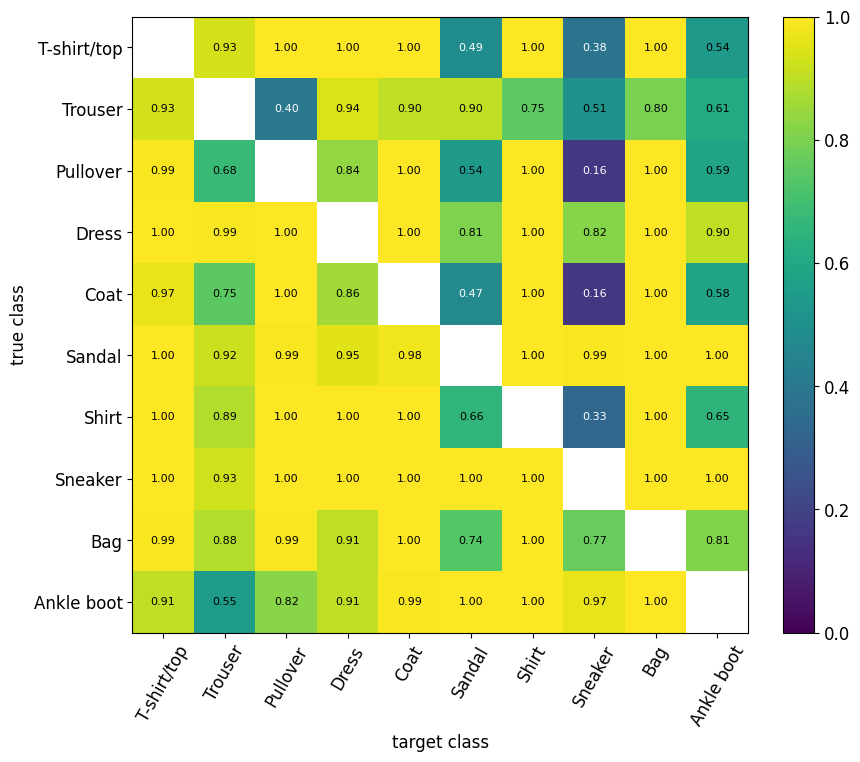

In [ ]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    S = targeted_success_matrix(model_a, XF_test, YF_test, eps=0.1)
    assert S.shape == (10, 10) and torch.isnan(S.diagonal()).all()
    pred_clean = predict_logits(model_a, XF_test).argmax(1)
    clean_confusion = torch.bincount((10 * YF_test + pred_clean).cpu(), minlength=100).reshape(10, 10).float()
    clean_confusion /= clean_confusion.sum(1, keepdim=True).clamp_min(1)
    print('Clean confusion matrix (строки: true, столбцы: predicted):')
    print(np.round(clean_confusion.numpy(), 2))

    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(S, cmap='viridis', vmin=0, vmax=1)
    for s, t in itertools.product(range(10), range(10)):
        if s != t:
            ax.text(t, s, f'{S[s, t]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if S[s, t] < 0.5 else 'black')
    ax.set_xticks(range(10), FM_CLASSES, rotation=60)
    ax.set_yticks(range(10), FM_CLASSES)
    ax.set_xlabel('target class')
    ax.set_ylabel('true class')
    plt.colorbar(im, fraction=0.046)
    plt.show()

**Вопрос.** Какие пары (истинный класс, целевой класс) атакуются легче всего, какие труднее? Симметрична ли матрица? Как это связано с тем, какие классы модель путает без атаки?

**Ответ.** Среди показанных пар легче всего атакуются Ankle boot → Bag, Ankle boot → Shirt и Ankle boot → Sandal: targeted attack срабатывает во всех случаях. Это тройка пар, которую выводит сводка; возможны и другие пары с таким же результатом. Труднее всего атаковать Coat → Sneaker — успех 15,65%, Pullover → Sneaker — 16,22% и Shirt → Sneaker — 32,99%.

Матрица несимметрична: среднее различие между парой направлений составляет 0,19649, или 19,65 п.п. Например, без атаки модель не путала Ankle boot с Bag и Shirt, хотя targeted attack переводила изображения в эти классы со стопроцентным успехом. Для пары Ankle boot → Sandal исходная ошибка была около 1,05%.

Значит, успешность атаки не определяется только тем, какие классы модель путает на обычных изображениях. Она также зависит от направления атаки и расположения границ между классами. В расчёте есть объекты, которые модель изначально классифицировала неверно, а в каждом классе — ограниченное число примеров. Поэтому вывод относится к этому запуску и выбранным настройкам PGD.

In [ ]:
# Численные наблюдения по фактическому запуску
if ATTACK_TRACK == 'targeted':
    pairs = [(float(S[s,t]), s, t) for s in range(10) for t in range(10) if torch.isfinite(S[s,t])]
    for label, rows in [('Трудные', sorted(pairs)[:3]), ('Лёгкие', sorted(pairs, reverse=True)[:3])]:
        for value, s, t in rows:
            print(label, FM_CLASSES[s], '→', FM_CLASSES[t], 'success=', value, 'clean confusion=', float(clean_confusion[s,t]))
    mask = torch.isfinite(S) & torch.isfinite(S.T)
    print('Средняя |S−S.T|:', (S-S.T).abs()[mask].mean().item())


Трудные Coat → Sneaker success= 0.156521737575531 clean confusion= 0.0
Трудные Pullover → Sneaker success= 0.1621621549129486 clean confusion= 0.0
Трудные Shirt → Sneaker success= 0.3298968970775604 clean confusion= 0.0
Лёгкие Ankle boot → Bag success= 1.0 clean confusion= 0.0
Лёгкие Ankle boot → Shirt success= 1.0 clean confusion= 0.0
Лёгкие Ankle boot → Sandal success= 1.0 clean confusion= 0.010526316240429878
Средняя |S−S.T|: 0.19649185240268707


## 5.3 Transfer (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'transfer'`. Ветку 5.2 при этом можно оставить пустой.

Black-box сценарий: атакующий не видит модель-жертву, строит атаку на своей модели и надеется, что она перенесётся. Обучите `model_b` (та же архитектура, `set_seed(1)`) и MLP с двумя скрытыми слоями по 512 нейронов и ReLU (`set_seed(2)`). Атаки FGSM и PGD-20 с $\varepsilon = 0.1$, построенные на `model_a`, проверьте на всех трёх моделях. Результат — `transfer[attack][victim] = accuracy`, атаки `'clean'`, `'FGSM'`, `'PGD-20'`, жертвы `'model A (source)'`, `'model B'`, `'MLP'`.

**Оценивание:** код — 0.6; эксперимент — 0.8; объяснение — 0.6 балла.

In [ ]:
if ATTACK_TRACK == 'transfer':
    # ваш код
    raise NotImplementedError
    print(f'{"":<8}' + ''.join(f'{name:>18}' for name in transfer['clean']))
    for attack, row in transfer.items():
        print(f'{attack:<8}' + ''.join(f'{acc:>18.3f}' for acc in row.values()))

**Вопрос.** Для каждой жертвы укажите падение accuracy относительно её собственного clean baseline. Сравните с падением на source-модели. Какая атака и на какую архитектуру переносится лучше в вашем прогоне? Предложите объяснение и укажите, почему одного seed недостаточно для общего вывода о превосходстве архитектуры или атаки.

**Ответ.** Ветка transfer не выбрана. по условию выполнена ветка targeted(5.2)


---
# 6. Adversarial training

## 6.1 PGD adversarial training (2 балла)

[Towards Deep Learning Models Resistant to Adversarial Attacks](https://arxiv.org/pdf/1706.06083), Madry et al., 2017:
$$
\min_\theta\; \mathbb E_{(x, y)} \Big[\max_{\|\delta\|_\infty \le \varepsilon} L\big(f_\theta(x + \delta), y\big)\Big].
$$
На каждом батче внутренний max приближается атакой, и шаг оптимизатора делается только по adversarial-примерам, без clean-части. Модель — с нуля.

Реализуйте `adversarial_train(model, eps, attack, epochs)`: `attack(model, x, y, eps)` возвращает detached `x_adv`. Используйте `torch.optim.Adam` с переданным `lr`, batch size 128, cross-entropy только на adversarial-примерах. Генерация атаки — в `eval()`, обновление весов — в `train()`; не дифференцируйте через построение атаки. После каждой эпохи записывайте clean, FGSM и PGD-20 accuracy на `XF_test[:1000]` с тем же $\varepsilon$. Перед возвратом включите `eval()` и очистите `.grad` параметров.

В обязательной части обучается одна модель с PGD-7. FGSM и FGSM-RS из готового словаря нужны только для бонуса 7.5.

**Оценивание:** код — 1; эксперимент — 0.6; объяснение — 0.4 балла.

In [ ]:
def fgsm_rs_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=1.25 * eps, steps=1, random_start=True)


def pgd7_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / 7, steps=7)


TRAIN_ATTACKS = {'FGSM': fgsm_attack, 'FGSM-RS': fgsm_rs_attack, 'PGD-7': pgd7_attack}
AT_EPOCHS = 2 if FAST_MODE else 5

In [ ]:
def adversarial_train(model, eps, attack, epochs=AT_EPOCHS, lr=1e-3, log=True):
    model = model.to(device)
    history = dict(clean=[], fgsm=[], pgd=[])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        for x, y in iterate_batches(XF_train, YF_train, 128):
            optimizer.zero_grad(set_to_none=True)
            model.eval()
            adv = attack(model, x, y, eps).detach()
            model.train()
            loss = F.cross_entropy(model(adv), y)
            loss.backward()
            optimizer.step()
        model.eval()
        model.zero_grad(set_to_none=True)
        for key, attack_fn in [('clean', None), ('fgsm', fgsm_attack), ('pgd', pgd)]:
            kwargs = {} if attack_fn is None else dict(eps=eps)
            history[key].append(attack_accuracy(model, XF_test[:1000], YF_test[:1000], attack_fn, batch_size=128, **kwargs))
        if log:
            print(epoch + 1, {k: round(v[-1], 4) for k, v in history.items()})
    model.eval()
    model.zero_grad(set_to_none=True)
    return history


In [ ]:
EPS_TRAIN = 0.1
robust, at_history = {}, {}
for name in ['PGD-7']:
    print(name)
    set_seed(0)
    robust[name] = SmallCNN()
    started = time.perf_counter()
    at_history[name] = adversarial_train(robust[name], EPS_TRAIN, TRAIN_ATTACKS[name])
    RUN_TIMES['fashion_pgd_at_seconds'] = time.perf_counter() - started
if not FAST_MODE and at_history['PGD-7']['pgd'][-1] <= 0.5:
    print('PGD accuracy ниже ориентира 0.5: проверьте обучение и обсудите результат; это не автопровал задания.')

PGD-7
1 {'clean': 0.807, 'fgsm': 0.695, 'pgd': 0.667}
2 {'clean': 0.804, 'fgsm': 0.699, 'pgd': 0.667}
3 {'clean': 0.819, 'fgsm': 0.716, 'pgd': 0.682}
4 {'clean': 0.84, 'fgsm': 0.739, 'pgd': 0.703}
5 {'clean': 0.826, 'fgsm': 0.731, 'pgd': 0.707}


In [ ]:
eps_grid = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3]
models_eval = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
torch.manual_seed(0)
robust_curves = {name: [attack_accuracy(m, XF_test, YF_test, pgd, eps=e) if e > 0 else attack_accuracy(m, XF_test, YF_test)
                        for e in eps_grid] for name, m in models_eval.items()}
for name, accs in robust_curves.items():
    print(f'{name:<10}' + ''.join(f'{a:>8.3f}' for a in accs))

standard     0.916   0.123   0.006   0.000   0.000   0.000
PGD-AT       0.826   0.775   0.708   0.515   0.147   0.001


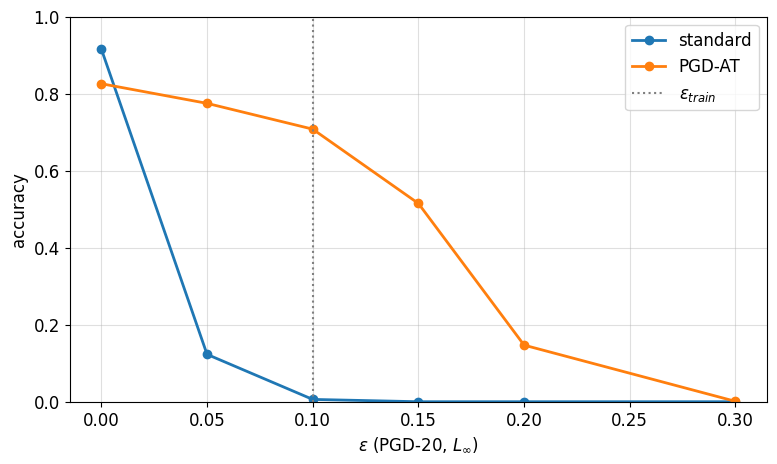

In [ ]:
plt.figure(figsize=(9, 5))
for name, accs in robust_curves.items():
    plt.plot(eps_grid, accs, 'o-', linewidth=2, label=name)
plt.axvline(EPS_TRAIN, color='gray', linestyle=':', label=r'$\varepsilon_{train}$')
plt.xlabel(r'$\varepsilon$ (PGD-20, $L_\infty$)')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Сколько стоит робастность в clean accuracy? Что происходит при $\varepsilon > \varepsilon_{\text{train}}$? Во сколько раз PGD-AT дороже обычного обучения по числу forward/backward?

**Ответ.** На чистых изображениях стандартная CNN показала accuracy 91,6%, а PGD-AT — 82,6%. В этом прогоне цена робастности составила 9 процентных пунктов. При ε = 0,1 PGD-20 снижает accuracy стандартной модели до 0,6%, тогда как у PGD-AT она равна 70,8%. При радиусе выше тренировочного качество PGD-AT постепенно падает: до 51,5% при ε = 0,15, 14,7% при ε = 0,2 и 0,1% при ε = 0,3. Значит, устойчивость к возмущениям радиуса εtrain не переносится автоматически на более крупные возмущения.

Для одного батча PGD-7-AT делает примерно семь проходов для построения атаки и ещё один для обновления параметров. По числу проходов это около восьми раз больше, чем обычное обучение. По замеру времени обучение PGD-AT заняло в 6,22 раза больше времени. Эти значения различаются, потому что вычисления для атаки и обновления параметров стоят по-разному; кроме того, функция обучения оценивает атаки после каждой эпохи.

In [ ]:
# Численные наблюдения по фактическому запуску
print('Стоимость в clean, п.п.:', 100*(robust_curves['standard'][0]-robust_curves['PGD-AT'][0]))
print('PGD-AT за пределами train eps:', [(e,a) for e,a in zip(eps_grid,robust_curves['PGD-AT']) if e>EPS_TRAIN])
print('Отношение времени обучения:', RUN_TIMES['fashion_pgd_at_seconds']/RUN_TIMES['fashion_standard_seconds'])


Стоимость в clean, п.п.: 9.000000000000007
PGD-AT за пределами train eps: [(0.15, 0.515), (0.2, 0.147), (0.3, 0.001)]
Отношение времени обучения: 6.215351083127622


## 6.2 Диагностика оценки robustness (1 балл)

Реализуйте `sanity_checks(model, x, y, eps)` и верните четыре accuracy:

- `fgsm` — после FGSM;
- `pgd20` — после PGD-20 с random start;
- `pgd100_x5` — PGD-100 с пятью random restarts: объект считается сломанным, если он ошибочно классифицирован хотя бы в одном restart **или уже на clean**;
- `eps_1` — после PGD-20 с $\varepsilon=1$.

Для каждого поля clean-ошибки тоже считаются ошибками: атака не должна «исправлять» robust accuracy. Атакуйте батчами не более 128. В `FAST_MODE` сокращается только число объектов, число шагов и restarts остаётся тем же.

Обычно усиление атаки уменьшает accuracy; обратный результат — повод проверить step size, random start и loss. Независимые конечные PGD-прогоны не дают гарантированного порядка результатов. Низкая accuracy при большом радиусе — полезная диагностика, но прохождение всех sanity checks не доказывает отсутствие gradient masking и не сертифицирует robustness. См. [Athalye et al., 2018](https://arxiv.org/abs/1802.00420).

Эксперимент проводится на фиксированных первых 128 объектах в FAST_MODE и 256 в финальном режиме. Это диагностика, а не точная оценка accuracy всего датасета.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [ ]:
def sanity_checks(model, x, y, eps):
    model.eval()
    totals = dict(fgsm=0, pgd20=0, pgd100_x5=0, eps_1=0)
    for start in range(0, len(x), 128):
        xb, yb = x[start:start + 128], y[start:start + 128]
        with torch.no_grad():
            clean_ok = model(xb).argmax(1).eq(yb)
        for key, fn, radius in [('fgsm', fgsm_attack, eps), ('pgd20', pgd, eps), ('eps_1', pgd, 1.0)]:
            adv = fn(model, xb, yb, radius)
            with torch.no_grad():
                totals[key] += (clean_ok & model(adv).argmax(1).eq(yb)).sum().item()
        survives = clean_ok.clone()
        for _ in range(5):
            adv = pgd(model, xb, yb, eps, steps=100)
            with torch.no_grad():
                survives &= model(adv).argmax(1).eq(yb)
        totals['pgd100_x5'] += survives.sum().item()
    return {key: value / len(x) for key, value in totals.items()}


In [ ]:
torch.manual_seed(0)
N_SANITY = 128 if FAST_MODE else 256
checks = {name: sanity_checks(m, XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_TRAIN)
          for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
print(f'{"model":<22}' + ''.join(f'{k:>11}' for k in next(iter(checks.values()))))
for name, res in checks.items():
    assert set(res) == {'fgsm', 'pgd20', 'pgd100_x5', 'eps_1'}
    assert all(math.isfinite(v) and 0 <= v <= 1 for v in res.values())
    print(f'{name:<22}' + ''.join(f'{v:>11.3f}' for v in res.values()))

model                        fgsm      pgd20  pgd100_x5      eps_1
standard                    0.082      0.012      0.008      0.000
PGD-AT                      0.762      0.727      0.715      0.000


**Вопрос.** Насколько меняется оценка accuracy при усилении атаки? Есть ли подозрительные результаты и что вы проверили бы дополнительно? Может ли модель с высокой FGSM accuracy и почти нулевой PGD accuracy пройти все перечисленные sanity checks — и что тогда можно сказать о её robustness?

**Ответ.** На фиксированных 256 объектах стандартная модель имеет FGSM accuracy 8.20%, PGD-20 — 1.17%, PGD-100×5 — 0.78%; усиление PGD снижает accuracy на 0.39 п.п. (один объект). Для PGD-AT значения равны 76.172%, 72.656% и 71.484%; снижение составляет 1.172 п.п. (три объекта). При ε=1 accuracy обеих моделей равна нулю, причём clean-ошибки учитываются как ошибки во всех полях.

Подозрительного повышения accuracy при усилении атаки в этом прогоне нет; небольшое падение для PGD-AT согласуется с устойчивостью к проверенным атакам, но не доказывает отсутствия gradient masking. Дополнительно можно проверить сетку step size и несколько seeds с объединением найденных ошибок по объектам. Модель с высокой FGSM accuracy и почти нулевой PGD accuracy может пройти перечисленные проверки порядка и большого радиуса, но робастной к PGD она не является. Эти числа относятся к 256 объектам, поэтому отличаются от оценок по 1000 объектам в разделе 6.1.


**Ответ.** На одних и тех же 256 объектах у стандартной модели accuracy снизилась с 8,20% на FGSM до 1,17% на PGD-20 и 0,78% на PGD-100×5. Усиление PGD уменьшило результат ещё на 0,39 п.п. У PGD-AT accuracy составила 76,17%, 72,66% и 71,48%; между PGD-20 и PGD-100×5 разница — 1,17 п.п. При ε = 1 accuracy обеих моделей равна нулю. В эту оценку входят и объекты, которые модель ошибочно классифицировала ещё до атаки.

В этом прогоне accuracy не повышается при усилении атаки, поэтому явного подозрительного результата нет. Но это не исключает gradient masking. Для дополнительной проверки можно изменить размер шага PGD и повторить оценку с несколькими случайными начальными точками.

Да, модель с высокой FGSM accuracy и почти нулевой PGD accuracy может пройти эти sanity checks: accuracy будет снижаться в ожидаемом порядке и упадёт до нуля при ε = 1. Но почти нулевая accuracy на PGD означает, что модель уязвима к проверенной PGD-атаке; считать её робастной нельзя. Результаты относятся к подвыборке из 256 объектов и могут отличаться от оценки на 1000 объектах в разделе 6.1.

In [ ]:
# Численные наблюдения по фактическому запуску
for name, row in checks.items():
    print(name, row, 'Δ pgd100_x5−pgd20=', row['pgd100_x5']-row['pgd20'])


standard {'fgsm': 0.08203125, 'pgd20': 0.01171875, 'pgd100_x5': 0.0078125, 'eps_1': 0.0} Δ pgd100_x5−pgd20= -0.00390625
PGD-AT {'fgsm': 0.76171875, 'pgd20': 0.7265625, 'pgd100_x5': 0.71484375, 'eps_1': 0.0} Δ pgd100_x5−pgd20= -0.01171875


## 6.3 Градиент по входу у обычной и робастной модели (1 балл)

Карта $|\nabla_x z_y(x)|$ — saliency по логиту верного класса: $z_c(x)$ обозначает логит класса $c$, $y$ — верную метку. Это **другая величина**, чем градиент cross-entropy в FGSM. Если $p_c(x)=\mathrm{softmax}(z(x))_c$, то
$$
\nabla_x L_{\mathrm{CE}}(x,y)=\sum_c p_c(x)\nabla_x z_c(x)-\nabla_x z_y(x).
$$
Для некоторых adversarially trained моделей наблюдали более интерпретируемые input gradients ([Tsipras et al., 2019](https://arxiv.org/pdf/1805.12152)). Здесь проверяется, наблюдается ли такой эффект в нашем протоколе; вид saliency сам по себе не доказывает robustness.

1. Реализуйте `input_gradient(model, x, y)`, возвращающую $|\nabla_x z_y|$ для батча (без изменения `.grad` параметров).
2. Для стандартной модели и PGD-AT посчитайте долю массы градиента на фоне (пиксели с $x = 0$), среднюю по `XF_test[:1000]`, и нарисуйте карты для 8 картинок.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [ ]:
def input_gradient(model, x, y):
    model.eval()
    gradients = []


    for i in range(len(x)):
        xi = x[i:i + 1].detach().clone().requires_grad_(True)

        with torch.enable_grad():
            score = model(xi)[0, y[i]]
            grad, = torch.autograd.grad(score, xi)

        gradients.append(grad.detach().abs())

    return torch.cat(gradients, dim=0)


def background_share(s, x):
    mass_background = (s * (x == 0)).flatten(1).sum(1)
    mass_total = s.flatten(1).sum(1).clamp_min(1e-12)
    return (mass_background / mass_total).mean().item()


In [ ]:
x, y = XF_test[:1000], YF_test[:1000]
g = input_gradient(model_a, x, y)
assert g.shape == x.shape and (g >= 0).all()
assert_no_param_grads(model_a)
x1 = x[:1].clone().requires_grad_(True)
manual, = torch.autograd.grad(model_a(x1)[0, y[0]], x1)
assert torch.allclose(g[:1], manual.abs())

grad_models = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
shares = {name: background_share(input_gradient(m, x, y), x) for name, m in grad_models.items()}
print(f'background pixels: {(x == 0).float().mean():.3f}')
shares

background pixels: 0.498


{'standard': 0.5930618643760681, 'PGD-AT': 0.21837233006954193}

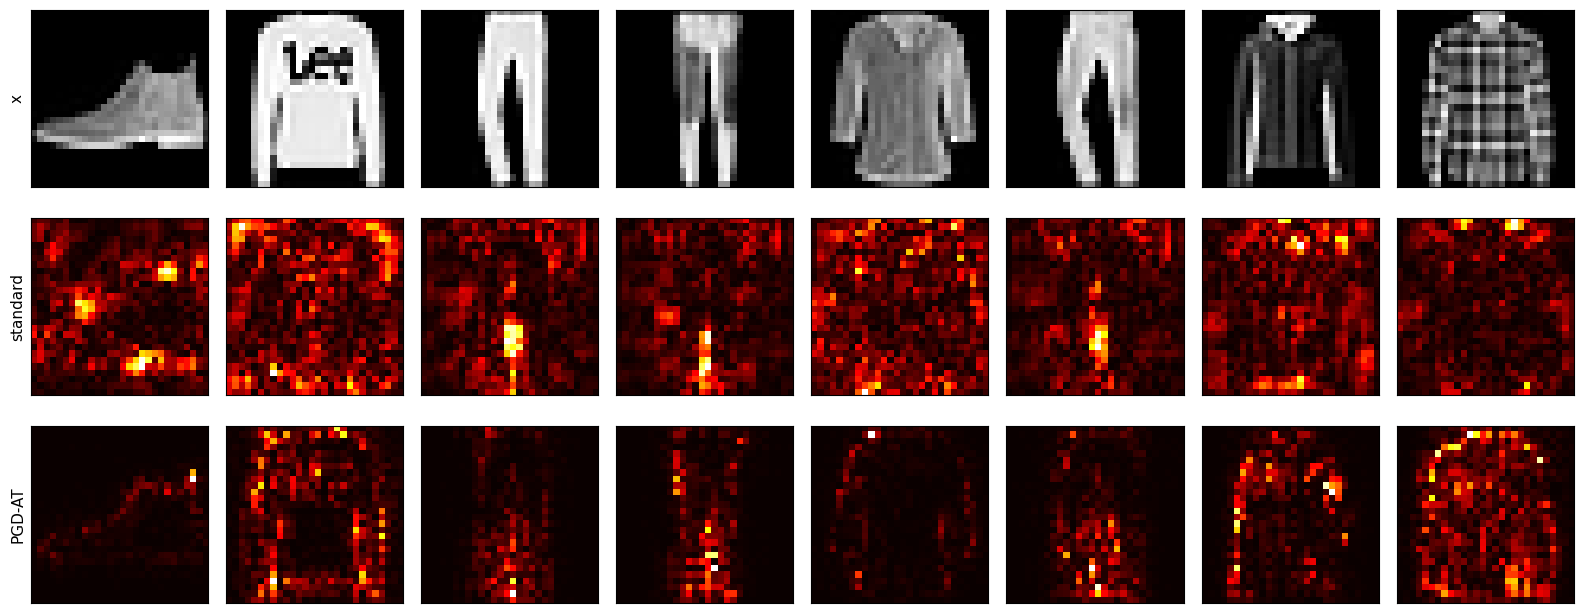

In [ ]:
x8, y8 = XF_test[:8], YF_test[:8]
rows = {'x': x8} | {name: input_gradient(m, x8, y8) for name, m in grad_models.items()}
fig, axes = plt.subplots(len(rows), 8, figsize=(16, 2.2 * len(rows)))
for row, (label, images) in enumerate(rows.items()):
    for i in range(8):
        axes[row, i].imshow(images[i, 0].cpu(), cmap='gray' if row == 0 else 'hot')
        axes[row, i].set_xticks([])
        axes[row, i].set_yticks([])
    axes[row, 0].set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()

**Вопрос.** Чем отличаются карты моделей — визуально и по доле массы на фоне? Согласуется ли наблюдение с различием PGD accuracy в вашем эксперименте? Почему одной красивой saliency-карты недостаточно для вывода о robustness?

**Ответ.** На восьми показанных изображениях карты PGD-AT чаще выделяют сам предмет и его границы. У стандартной модели заметнее отклики на фоне и по краям, хотя это различие видно не на каждом изображении. На первых 1000 тестовых объектах фон занимает 49,8% пикселей. На него приходится в среднем 59,31% массы градиента стандартной модели и 21,84% у PGD-AT — разница составляет 37,47 п.п.

Это согласуется с результатами PGD-атаки: на диагностических 256 объектах PGD accuracy составила 1,172% у стандартной модели и 72,656% у PGD-AT. На выборке из 1000 объектов при ε = 0,1 результаты были 0,6% и 70,8% соответственно. Однако по этим данным нельзя заключить, что именно карты градиентов стали причиной разницы в устойчивости.

Saliency-карта показывает мне градиент верного логита, а атака использует градиент функции потерь и ограниченное возмущение. Поэтому даже понятная на вид карта сама по себе не доказывает это, что модель устойчива к атакам. Кроме того, цветовая шкала каждой карты настроена отдельно, так что яркость между моделями напрямую сравнивать нельзя

In [ ]:
# Численные наблюдения по фактическому запуску
print('Масса на фоне:', shares)
print('PGD accuracy (диагностическая подвыборка):', {name: row['pgd20'] for name,row in checks.items()})


Масса на фоне: {'standard': 0.5930618643760681, 'PGD-AT': 0.21837233006954193}
PGD accuracy (диагностическая подвыборка): {'standard': 0.01171875, 'PGD-AT': 0.7265625}


### Сохранение результатов обязательной части

Ячейка сохраняет `metrics.json` и три checkpoint в `artifacts/`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode=false`. Сдайте их вместе с ноутбуком. NaN в матрице targeted success записываются как JSON `null`. Checkpoints содержат только `state_dict`, без сериализации объекта модели.

In [ ]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    schema_version=2, fast_mode=FAST_MODE, attack_track=ATTACK_TRACK,
    environment=dict(torch=torch.__version__, device=str(device)),
    data=dict(cifar_train=len(X_train), cifar_test=len(X_test),
              fashion_train=len(XF_train), fashion_test=len(XF_test)),
    config=dict(seed=0, cifar_epochs=EPOCHS, ablation_epochs=ABL_EPOCHS,
                cifar_lr=LR, cifar_mean=CIFAR_MEAN, cifar_std=CIFAR_STD,
                fashion_epochs=FM_EPOCHS, at_epochs=AT_EPOCHS, eps_train=EPS_TRAIN),
    cifar=dict(history=history_cifar, ablations=ablation),
    attacks=dict(l2_eps=eps_l2, l2_accuracy=acc_l2, linf_accuracy=acc_linf,
                 selected=S if ATTACK_TRACK == 'targeted' else transfer),
    adversarial=dict(history=at_history, eps=eps_grid, accuracy=robust_curves,
                     sanity=checks, background_share=shares),
    timings=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2,
                                                    allow_nan=False), encoding='utf-8')
for name, model in [('resnet20', resnet20), ('fashion_standard', model_a), ('fashion_pgd_at', robust['PGD-7'])]:
    torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, artifact_dir / f'{name}.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['fashion_pgd_at.pt', 'fashion_standard.pt', 'metrics.json', 'resnet20.pt']


---
# 7\*. Бонусные задачи

## 7.1 Edge of stability (1.5 балла)

Для положительно определённой квадратичной функции GD сходится при $0 < \eta < 2/\lambda_{\max}$, где $\lambda_{\max}$ — наибольшее собственное число гессиана. [Gradient Descent on Neural Networks Typically Occurs at the Edge of Stability](https://arxiv.org/pdf/2103.00065), Cohen et al., 2021: у нейросети sharpness $\lambda_{\max}(\nabla^2 L)$ во время full-batch GD растёт (progressive sharpening), пока не дойдёт до $2/\eta$, и дальше держится около этой границы — loss при этом немонотонный, но продолжает убывать.

1. Реализуйте `hvp(grads, params, v)`: градиент считается один раз с `create_graph=True`, а $Hv$ — VJP градиента с вектором $v$ (`grad_outputs` в `torch.autograd.grad`); гессиан $H$ явно не строится.
2. `top_eigenvalue` ниже — готовый Lanczos с reorthogonalization. Он оценивает **наибольшее algebraic eigenvalue** через наибольшее eigenvalue небольшой tridiagonal matrix. Обычная power iteration для indefinite Hessian может найти отрицательное eigenvalue с наибольшим модулем и здесь не подходит. Менять готовый solver не требуется; проверьте HVP и solver на тестах, включая indefinite quadratic.
3. Full-batch GD (`SGD` без momentum) для MLP с двумя скрытыми слоями по 200 нейронов и tanh на первых 2000 картинках FashionMNIST, loss — MSE по one-hot $\frac12 \|f(x) - e_y\|^2$ (среднее по объектам). Для нескольких $\eta$ записывать loss на каждом шаге и $\lambda_{\max}$ каждые 50 шагов. График: $\lambda_{\max}$ по шагам с горизонталями $2/\eta$.

**Оценивание:** код — 0.7; эксперимент — 0.4; объяснение — 0.4 балла.

In [ ]:
if '7.1' in BONUS_TASKS:
    def hvp(grads, params, v):
        # grads = torch.autograd.grad(loss, params, create_graph=True); v — список тензоров формы params
        # ваш код
        raise NotImplementedError


    def top_eigenvalue(loss_fn, params, iters=20, v=None):
        # Готовый solver: largest algebraic Ritz value, не eigenvalue наибольшего модуля.
        params = list(params)
        sizes = [p.numel() for p in params]
        total = sum(sizes)
        if iters < 1:
            raise ValueError('iters must be positive')
        def unpack(flat):
            return [part.view_as(p) for part, p in zip(flat.split(sizes), params)]
        q = torch.randn(total, device=params[0].device, dtype=params[0].dtype)
        if v is not None:
            # Небольшой шум не даёт warm start застрять в одном инвариантном подпространстве.
            q = torch.cat([vi.detach().flatten() for vi in v]) + 1e-3 * q / q.norm()
        q = q / q.norm()
        grads = torch.autograd.grad(loss_fn(), params, create_graph=True)
        basis, diagonal, off_diagonal = [], [], []
        for k in range(min(iters, total)):
            basis.append(q)
            z = torch.cat([h.detach().flatten() for h in hvp(grads, params, unpack(q))])
            if k:
                z = z - off_diagonal[-1] * basis[-2]
            alpha = torch.dot(q, z)
            diagonal.append(alpha)
            z = z - alpha * q
            Q = torch.stack(basis)
            for _ in range(2):
                z = z - (Q @ z) @ Q
            beta = z.norm()
            if beta.item() < 1e-7 or k + 1 == min(iters, total):
                break
            off_diagonal.append(beta)
            q = z / beta
        T = torch.diag(torch.stack(diagonal))
        if off_diagonal:
            off = torch.stack(off_diagonal)
            T += torch.diag(off, diagonal=1) + torch.diag(off, diagonal=-1)
        # Маленькая eigenproblem на CPU, в том числе при основном обучении на MPS.
        values, vectors = torch.linalg.eigh(T.cpu().double())
        coeffs = vectors[:, -1].to(device=q.device, dtype=q.dtype)
        eigenvector = coeffs @ torch.stack(basis)
        return values[-1].item(), unpack(eigenvector)

In [ ]:
if '7.1' in BONUS_TASKS:
    torch.manual_seed(0)
    Q = torch.linalg.qr(torch.randn(30, 30))[0]
    A = Q @ torch.diag(torch.linspace(0.1, 7, 30)) @ Q.T
    w = torch.randn(30, requires_grad=True)
    grads = torch.autograd.grad(0.5 * w @ A @ w, [w], create_graph=True)
    v = torch.randn(30)
    assert torch.allclose(hvp(grads, [w], [v])[0], A @ v, atol=1e-5)

    p = torch.tensor([1.0, -2.0], requires_grad=True)
    lam, _ = top_eigenvalue(lambda: 0.5 * (p[0] ** 2 + 20 * p[1] ** 2), [p], iters=50)
    assert abs(lam - 20) < 1e-3
    lam, _ = top_eigenvalue(lambda: 0.5 * w @ A @ w, [w], iters=300)
    assert abs(lam - 7) < 1e-2
    lam, _ = top_eigenvalue(lambda: 0.5 * (-10 * p[0] ** 2 + 2 * p[1] ** 2), [p], iters=10)
    assert abs(lam - 2) < 1e-4, lam

In [ ]:
if '7.1' in BONUS_TASKS:
    N_EOS = 256 if FAST_MODE else 2000
    EOS_STEPS = 100 if FAST_MODE else 3000
    X_eos = XF_train[:N_EOS].flatten(1)
    X_eos = X_eos - X_eos.mean(dim=0)
    Y_eos = F.one_hot(YF_train[:N_EOS], 10).float()


    def make_tanh_mlp(seed=0):
        torch.manual_seed(seed)
        return nn.Sequential(nn.Linear(784, 200), nn.Tanh(), nn.Linear(200, 200), nn.Tanh(), nn.Linear(200, 10)).to(device)


    def mse_loss(model):
        return 0.5 * ((model(X_eos) - Y_eos) ** 2).sum(dim=1).mean()

In [ ]:
if '7.1' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** В каких прогонах sharpness приблизилась к $2/\eta$? Если выхода на границу не было, укажите это. Сопоставьте изменения sharpness и loss. Почему локальный критерий для фиксированной положительно определённой квадратичной функции не гарантирует такую же динамику нелинейной сети?

**Ответ.** Бонусная задача не выбрана (`BONUS_TASKS=set()`); эксперимент не выполнялся.


## 7.2 Свёртка через FFT со stride, padding и groups (0.5 балла)

Теорема о свёртке: $\mathcal F(x * w) = \mathcal F(x) \cdot \mathcal F(w)$. Детали:

- DFT считает циклическую свёртку — дополняем нулями до $H + k_h - 1$ по высоте и $W + k_w - 1$ по ширине;
- `F.conv2d` — cross-correlation, поэтому ядро переворачивается;
- сумма по входным каналам остаётся суммой в частотной области; с `groups` — только внутри группы;
- padding — `F.pad` входа; stride $s$ — прореживание «valid»-результата $[\,::s,\; ::s\,]$.

Реализуйте `conv2d_fft` (dilation = 1; stride и padding — целые числа) через `torch.fft.rfft2` / `irfft2` и `einsum`.

**Оценивание:** код — 0.4; эксперимент — 0; объяснение — 0.1 балла.

In [ ]:
if '7.2' in BONUS_TASKS:
    def conv2d_fft(x, weight, bias=None, stride=1, padding=0, groups=1):
        # ваш код
        raise NotImplementedError

In [ ]:
if '7.2' in BONUS_TASKS:
    torch.manual_seed(0)
    x = torch.randn(2, 4, 13, 10)
    n_checked = 0
    for k, s, p, g in itertools.product([1, 3, (3, 5)], [1, 2, 3], [0, 1, 2], [1, 2, 4]):
        w, b = torch.randn(8, 4 // g, *pair(k)), torch.randn(8)
        ref = F.conv2d(x, w, b, stride=s, padding=p, groups=g)
        out = conv2d_fft(x, w, b, stride=s, padding=p, groups=g)
        assert out.shape == ref.shape and torch.allclose(out, ref, atol=1e-4), (k, s, p, g)
        n_checked += 1
    n_checked

**Вопрос.** Какую долю посчитанных выходов FFT-свёртка выбрасывает при stride $s$? Когда FFT-свёртка всё равно выгоднее прямой?

**Ответ.** Бонусная задача не выбрана (`BONUS_TASKS=set()`); эксперимент не выполнялся.


## 7.3 Muon для свёрточных весов (1 балл)

[Muon: An optimizer for hidden layers in neural networks](https://kellerjordan.github.io/posts/muon/), Jordan et al., 2024. Для матричного параметра $W \in \mathbb R^{m \times n}$ с градиентом $G_t$ — так он устроен в `torch.optim.Muon` (momentum через EMA, Nesterov):
$$
B_t = \mu B_{t-1} + (1 - \mu)\, G_t, \qquad U_t = (1 - \mu)\, G_t + \mu B_t, \qquad
W \leftarrow W - \eta \sqrt{\max(1,\, m/n)}\; \mathrm{NS}_5(U_t),
$$
где $\mathrm{NS}_5$ — 5 итераций Ньютона–Шульца, приближающие ортогональный множитель $P Q^\top$ из SVD $U_t = P \Sigma Q^\top$:
$$
X_0 = \frac{U_t}{\|U_t\|_F}, \qquad X_{j+1} = a X_j + b\, (X_j X_j^\top) X_j + c\, (X_j X_j^\top)^2 X_j, \qquad (a, b, c) = (3.4445,\, -4.7750,\, 2.0315)
$$
(если $m > n$, итерации идут для $X^\top$). `torch.optim.Muon` принимает только 2D-параметры, а вес свёртки $(C_{\text{out}}, C_{\text{in}}, k, k)$ — это матрица $C_{\text{out}} \times C_{\text{in}} k^2$ (та же, что в `conv2d_unfold`).

1. Реализуйте `newton_schulz` и `ConvMuon` (без weight decay) для параметров любой размерности $\ge 2$: первая ось — строки, остальные разворачиваются в столбцы. Библиотечный Muon считает итерации в bfloat16, поэтому сравнение с ним — с допуском.
2. Обучите ResNet-20: `ConvMuon` с `MUON_LR` для всех 4D-весов, `MyAdamW` как в `train_cifar` для остального (BN, голова), у обоих cosine schedule, бюджет `EPOCHS`, тот же `set_seed(0)`. Сравните с `history_cifar` из 4.2. Здесь сравниваются два фиксированных training recipe, включая разный weight decay на conv-весах; этот опыт не изолирует влияние одного лишь optimizer и не является общим рейтингом.

**Оценивание:** код — 0.5; эксперимент — 0.3; объяснение — 0.2 балла.

In [ ]:
if '7.3' in BONUS_TASKS:
    def newton_schulz(M, steps=5, coeffs=(3.4445, -4.7750, 2.0315)):
        # ваш код
        raise NotImplementedError


    class ConvMuon(torch.optim.Optimizer):
        def __init__(self, params, lr=0.02, momentum=0.95):
            super().__init__(params, dict(lr=lr, momentum=momentum))

        @torch.no_grad()
        def step(self):
            for group in self.param_groups:
                mu = group['momentum']
                for p in group['params']:
                    if p.grad is None:
                        continue
                    # ваш код
                    raise NotImplementedError

In [ ]:
if '7.3' in BONUS_TASKS:
    def muon_steps(make_optimizer, shape, steps=5):
        torch.manual_seed(0)
        p = torch.randn(shape, requires_grad=True)
        optimizer = make_optimizer(p)
        gen = torch.Generator().manual_seed(1)
        for _ in range(steps):
            optimizer.zero_grad()
            (p * torch.randn(shape, generator=gen)).sum().backward()
            optimizer.step()
        return p.detach()


    torch.manual_seed(0)
    M = torch.randn(64, 32) * torch.logspace(0, -3, 32)
    assert torch.linalg.svdvals(newton_schulz(M)).max() < 1.3

    for shape in [(48, 20), (20, 48)]:
        start = muon_steps(lambda p: torch.optim.SGD([p], lr=0.0), shape)   # lr = 0: начальная точка
        mine = muon_steps(lambda p: ConvMuon([p], lr=0.02), shape)
        ref = muon_steps(lambda p: torch.optim.Muon([p], lr=0.02, weight_decay=0.0), shape)
        assert ((mine - ref).norm() / (ref - start).norm()) < 0.05, shape

    conv_w = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 8, 3, 3))
    flat = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 72))
    assert torch.allclose(conv_w.view(16, 72), flat, atol=1e-6)

In [ ]:
if '7.3' in BONUS_TASKS:
    MUON_LR = 0.02
    # ваш код
    raise NotImplementedError
    hist_adamw = history_cifar
    print(f'{"":<10}{"train loss":>12}{"test acc":>10}')
    for name, hist in [('AdamW', hist_adamw), ('Muon', hist_muon)]:
        print(f'{name:<10}{hist["train_loss"][-1]:>12.4f}{hist["test_acc"][-1]:>10.4f}')

In [ ]:
if '7.3' in BONUS_TASKS:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    for name, hist in [('AdamW', hist_adamw), ('Muon (conv) + AdamW', hist_muon)]:
        epochs_axis = range(1, len(hist['test_acc']) + 1)
        ax1.semilogy(epochs_axis, hist['train_loss'], 'o-', label=name)
        ax2.plot(epochs_axis, hist['test_acc'], 'o-', label=name)
    ax1.set_ylabel('train loss')
    ax2.set_ylabel('test accuracy')
    for ax in (ax1, ax2):
        ax.set_xlabel('epoch')
        ax.grid(True, which='both', alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()

**Вопрос.** Какой оптимизатор быстрее снижает train loss и какой даёт лучшую test accuracy при том же бюджете? Сколько памяти состояния на параметр у каждого?

**Ответ.** Бонусная задача не выбрана (`BONUS_TASKS=set()`); эксперимент не выполнялся.


## 7.4 $L_0$-атака на $L_\infty$-робастную модель (1 балл)

Ограничение — число изменённых пикселей:
$$
\max_{\|\delta\|_0 \le k,\;\; x + \delta \in [0, 1]^d} L\big(f(x + \delta), y\big).
$$
Линеаризация: пиксель $i$ выгоднее всего довести до 0 или до 1, прирост loss
$$
\mathrm{gain}_i = \max\big(g_i (1 - x_i),\; -g_i\, x_i\big), \qquad g = \nabla_x L.
$$
Жадная атака: $k$ раз пересчитать градиент и изменить ещё не тронутый пиксель с максимальным $\mathrm{gain}_i$ — на 1, если $g_i > 0$, иначе на 0.

1. Используйте готовую `greedy_pixel_attack` из семинара 4 ниже; переписывать её не требуется. Баллы — за эксперимент и интерпретацию.
2. Accuracy от $k$ для стандартной модели и PGD-AT на `XF_test[:500]`.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [ ]:
if '7.4' in BONUS_TASKS:
    def greedy_pixel_attack(model, x, y, k):
        x_adv = x.detach().clone()
        changed = torch.zeros_like(x_adv, dtype=torch.bool)
        for _ in range(k):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y, reduction='sum'), x_adv)
            x_adv = x_adv.detach()
            gain = torch.maximum(grad * (1 - x_adv), -grad * x_adv).masked_fill(changed, -float('inf'))
            idx = gain.flatten(1).argmax(dim=1, keepdim=True)
            new_val = (grad.flatten(1).gather(1, idx) > 0).float()
            x_adv = x_adv.flatten(1).scatter(1, idx, new_val).view_as(x)
            changed = changed.flatten(1).scatter(1, idx, True).view_as(x)
        return x_adv

In [ ]:
if '7.4' in BONUS_TASKS:
    x, y = XF_test[:500], YF_test[:500]
    x5 = greedy_pixel_attack(model_a, x, y, k=5)
    n_changed = ((x5 - x).flatten(1) != 0).sum(dim=1)
    assert n_changed.max() <= 5 and x5.min() >= 0 and x5.max() <= 1
    assert torch.isin(x5[x5 != x], torch.tensor([0.0, 1.0], device=x.device)).all()
    assert_no_param_grads(model_a)
    print({'clean': attack_accuracy(model_a, x, y), 'L0, k=5': attack_accuracy(model_a, x5, y)})

    ks = [0, 1, 2, 3, 5, 10, 20, 30]
    l0_curves = {name: [attack_accuracy(m, greedy_pixel_attack(m, x, y, k), y) for k in ks]
                 for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
    for name, accs in l0_curves.items():
        print(f'{name:<10}' + ''.join(f'{a:>7.3f}' for a in accs))

In [ ]:
if '7.4' in BONUS_TASKS:
    plt.figure(figsize=(9, 5))
    for name, accs in l0_curves.items():
        plt.plot(ks, accs, 'o-', linewidth=2, label=name)
    plt.xlabel(r'$k = \|\delta\|_0$ (changed pixels)')
    plt.ylabel('accuracy')
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(True, alpha=0.4)
    plt.show()

**Вопрос.** Помогает ли робастность в $L_\infty$ против $L_0$-атаки? Почему $L_\infty$-шар радиуса $\varepsilon$ не защищает от изменения одного пикселя с 0 до 1?

**Ответ.** Бонусная задача не выбрана (`BONUS_TASKS=set()`); эксперимент не выполнялся.


## 7.5 Catastrophic overfitting (1 балл)

Включается через `'7.5'` в `BONUS_TASKS`; нужны функции из 6.1 и 6.2. Обучите две дополнительные модели с готовыми FGSM и FGSM-RS при `EPS_CO=0.2`. FGSM-RS начинает из случайной точки, делает один шаг размера $1.25\varepsilon$ и проецируется обратно в допустимое множество.

В работе [Wong et al., 2020](https://arxiv.org/pdf/2001.03994) описано catastrophic overfitting: PGD accuracy резко падает, хотя FGSM accuracy остаётся высокой. Random start может помочь, но ни возникновение эффекта за наш бюджет, ни его устранение не гарантированы.

Код обучения и графика дан; баллы — за диагностику и объяснение. Не меняйте эпохи или радиус только ради получения «нужной картинки». Если добавите контрольный опыт, запишите его настройки отдельно.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [ ]:
if '7.5' in BONUS_TASKS:
    EPS_CO = 0.2
    co_history = {}
    for name in ['FGSM', 'FGSM-RS']:
        print(name)
        set_seed(0)
        robust[f'{name}, eps={EPS_CO}'] = SmallCNN()
        co_history[name] = adversarial_train(robust[f'{name}, eps={EPS_CO}'], EPS_CO, TRAIN_ATTACKS[name])

In [ ]:
if '7.5' in BONUS_TASKS:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for ax, (name, hist) in zip(axes, co_history.items()):
        epochs_axis = range(1, len(hist['clean']) + 1)
        for key, label in [('clean', 'clean'), ('fgsm', 'FGSM'), ('pgd', 'PGD-20')]:
            ax.plot(epochs_axis, hist[key], 'o-', linewidth=2, label=label)
        ax.set_title(f'{name}-AT, eps = {EPS_CO}')
        ax.set_xlabel('epoch')
        ax.grid(True, alpha=0.4)
    axes[0].set_ylabel('accuracy')
    axes[0].set_ylim(0, 1)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

In [ ]:
if '7.5' in BONUS_TASKS:
    co_checks = {name: sanity_checks(robust[f'{name}, eps={EPS_CO}'], XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_CO)
                 for name in ['FGSM', 'FGSM-RS']}
    print(co_checks)

**Вопрос.** Был ли резкий спад PGD accuracy и на какой эпохе? Изменил ли картину random start? Сопоставьте динамику FGSM/PGD и результаты усиленной атаки. Если catastrophic overfitting не наблюдается, укажите это и предложите одну проверяемую гипотезу о том, от чего он мог бы зависеть.

**Ответ.** Бонусная задача не выбрана (`BONUS_TASKS=set()`); эксперимент не выполнялся.


In [ ]:
import shutil
from google.colab import files

shutil.make_archive('artifacts', 'zip', '.', 'artifacts')
files.download('artifacts.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>